<div style="background-color:blue"><h1 style="color:black;text-align:center">PROJET : TARIFICATION EN ASSURANCE AUTOMOBILE</h1></div>


<h1 style="color: blue; text-align: center">importation des bibliothèques</h1>

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

# --- Modèles scikit-learn ---
from sklearn.model_selection import (
    train_test_split, cross_val_score,
    GridSearchCV, KFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import (
    Ridge, RidgeCV, Lasso, LassoCV, lasso_path
)
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline


# Reproductibilité 
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Style des graphiques 
plt.rcParams.update({
    'figure.dpi'      : 120,
    'figure.figsize'  : (12, 5),
    'axes.titlesize'  : 13,
    'axes.labelsize'  : 11,
    'xtick.labelsize' : 9,
    'ytick.labelsize' : 9,
})
sns.set_theme(style='whitegrid', palette='muted')

<h1 style="color: blue; text-align: center">OBSERVATION ET ANALYSE EXPLORATOIRE DE LA BASE DE DONNEES</h1>
<h2 style="color: cyan; text-align: center">chargement du jeu de donnees</h2>

mettons nos donnees dans les variables freq et sev (freMTPL2freq et freMTPL2sev respectivement) pour les manipuler

In [ ]:
freq = pd.read_csv("freMTPL2freq.csv")
sev  = pd.read_csv("freMTPL2sev.csv")

Jointure pour le modèle de sévérité

In [3]:
# Sévérité moyenne par police (pour les polices avec au moins un sinistre)
sev_agg = sev.groupby('IDpol')['ClaimAmount'].mean().reset_index()
sev_agg.columns = ['IDpol', 'AvgSeverity']
# Jointure pour le modèle de sévérité
freq_sev = freq.merge(sev_agg, on='IDpol', how='inner')

affichons les cinq premieres lignes

In [4]:
freq.head(5)

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1,1,0.10,D,5,0,55,50,B12,Regular,1217,R82
1,3,1,0.77,D,5,0,55,50,B12,Regular,1217,R82
2,5,1,0.75,B,6,2,52,50,B12,Diesel,54,R22
3,10,1,0.09,B,7,0,46,50,B12,Diesel,76,R72
4,11,1,0.84,B,7,0,46,50,B12,Diesel,76,R72


In [5]:
sev.head(5)

,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


<h2 style="color: cyan; text-align: center">dimension des jeux de donnees</h2>

In [6]:
print(f"on a {freq.shape[0]} lignes et {freq.shape[1]} colones(features) pour la Table de fréquence et \n")
print(f"on a {sev.shape[0]} lignes et {sev.shape[1]} colones(features) pour la Table de sévérité\n")


on a 678013 lignes et 12 colones(features) pour la Table de fréquence et 

on a 26639 lignes et 2 colones(features) pour la Table de sévérité



In [7]:
freq.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  int64  
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   Area        678013 non-null  object 
 4   VehPower    678013 non-null  int64  
 5   VehAge      678013 non-null  int64  
 6   DrivAge     678013 non-null  int64  
 7   BonusMalus  678013 non-null  int64  
 8   VehBrand    678013 non-null  object 
 9   VehGas      678013 non-null  object 
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  object 
dtypes: float64(1), int64(7), object(4)
memory usage: 62.1+ MB


In [8]:
sev.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol        26639 non-null  int64  
 1   ClaimAmount  26639 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 416.4 KB


<h2 style="color: cyan; text-align: center">description des variables</h2>

Fréquences

<div><style>
            table{
                width: 100%;
                margin: 20px auto;
                text-align: center;
                background-color: whitesmoke;
                border-style: solid;
                border-color: rgba(74, 70, 70, 1);
            }
            tr td{
                width: 50px
                border-style: solid;
                border-color: #000;
                background-color:whitesmoke;
                color: black;
            }
            body{
                background-color: whitesmoke;
            }
    </style>
    <table style="border-collapse: collapse; text-align: center;">
            <tr>
                <td><u>VARIABLE</u><br/></td>
                <td><u>DESCRIPTION</u><br/></td>
                <td><u>TYPE</u><br/></td>
            </tr>
            <tr>
                <td><b>IDpol</b><br/></td>
                <td  style="text-align: left;">identifiant unique pour la police d'assurance<br/></td>
                <td><b>Identifiant</b><br/></td>
            </tr>
            <tr>
                <td><b>ClaimNb</b><br/></td>
                <td style="text-align: left;">Nombre de sinistres déclarés<br/></td>
                <td><b>Entier</b><br/></td>
            </tr>
            <tr>
                <td><b>Exposure</b><br/></td>
                <td style="text-align: left;">Durée du contrat en années<br/></td>
                <td><b>float  ∈ (0,1]</b><br/></td>
            </tr>
            <tr>
                <td><b>Area</b><br/></td>
                <td style="text-align: left;">Zone géographique (densité croissante)<br/></td>
                <td><b>Catégoriel (A–F)</b><br/></td>
            </tr>
            <tr>
                <td><b>VehPower</b><br/></td>
                <td style="text-align: left;">Puissance du véhicule<br/></td>
                <td><b>Int</b><br/></td>
            </tr>
            <tr>
                <td><b>VehAge</b><br/></td>
                <td style="text-align: left;">Âge du véhicule (années)<br/></td>
                <td><b>Int</b><br/></td>
            </tr>
            <tr>
                <td><b>DrivAge</b><br/></td>
                <td style="text-align: left;">Âge du conducteur principal<br/></td>
                <td><b>Int</b><br/></td>
            </tr>
            <tr>
                <td><b>BonusMalus</b><br/></td>
                <td style="text-align: left;">Coefficient bonus-malus (50–350)<br/></td>
                <td><b>Int</b><br/></td>
            </tr>
            <tr>
                <td><b>VehBrand</b><br/></td>
                <td style="text-align: left;">Marque du véhicule<br/></td>
                <td><b>Catégoriel (B1–B14)</b><br/></td>
            </tr>
            <tr>
                <td><b>VehGas</b><br/></td>
                <td style="text-align: left;">Carburant <br/></td>
                <td><b>Catégoriel (Regular / Diesel)</b><br/></td>
            </tr>
            <tr>
                <td><b>Density</b><br/></td>
                <td style="text-align: left;">le nombre d'habitants dans la region du client<br/></td>
                <td><b>int</b><br/></td>
            </tr>
            <tr>
                <td><b>Region</b><br/></td>
                <td style="text-align: left;">Région administrative<br/></td>
                <td><b>Catégoriel (22 modalités) </b><br/></td>
            </tr>
    </table>
</div>

Sévérité

<div><style>
            table{
                width: 100%;
                margin: 20px auto;
                text-align: center;
                background-color: whitesmoke;
                border-style: solid;
                border-color: rgba(74, 70, 70, 1);
            }
            tr td{
                width: 50px
                border-style: solid;
                border-color: #000;
                background-color:whitesmoke;
                color: black;
            }
            body{
                background-color: whitesmoke;
            }
    </style>
    <table style="border-collapse: collapse; text-align: center;">
            <tr>
                <td><u>VARIABLE</u><br/></td>
                <td><u>DESCRIPTION</u><br/></td>
                <td><u>TYPE</u><br/></td>
            </tr>
            <tr>
                <td><b>IDpol</b><br/></td>
                <td  style="text-align: left;">identifiant unique pour la police d'assurance<br/></td>
                <td><b>Identifiant</b><br/></td>
            </tr>
            <tr>
                <td><b>ClaimAmount</b><br/></td>
                <td style="text-align: left;">Montant du sinistre (€)<br/></td>
                <td><b>float</b><br/></td>
            </tr>
    </table>
</div>

<h2 style="color: cyan; text-align: center">gestion des valeurs manquantes</h2>
visualisons mieux les features ayant des valeurs manquantes

In [9]:
#pourcentage de valeurs manquantes (frequences)
freq.isnull().sum() * 100 / len(freq)

IDpol         0.0
ClaimNb       0.0
Exposure      0.0
Area          0.0
VehPower      0.0
VehAge        0.0
DrivAge       0.0
BonusMalus    0.0
VehBrand      0.0
VehGas        0.0
Density       0.0
Region        0.0
dtype: float64

In [10]:
#pourcentage de valeurs manquantes (severite)
sev.isnull().sum() * 100 / len(sev)

IDpol          0.0
ClaimAmount    0.0
dtype: float64

Nous n'avons donc aucune valeur manquante dans nos bases de donées

<h2 style="color: cyan; text-align: center">gestion des doublons</h2>
Identifions les doublons

In [11]:
print("Nombre total de lignes doublons pour la Table Frequences : ", freq.duplicated().sum())
print("Nombre total de lignes doublons pour la Table Sévérité : ", sev.duplicated().sum())

Nombre total de lignes doublons pour la Table Frequences :  0
Nombre total de lignes doublons pour la Table Sévérité :  261


On constate qu'on a aucun doublon dans la table des fréquences (on a pas de polices dupliquée)

Pour la table des Sévérité, on a 261 doublons, ce qui signifie que certains assués on eu à déclarer un signistre plusieurs fois.

Dans les deux cas, nos modèles ne sont pas compromis

<h2 style="color: cyan; text-align: center">gestion des formats</h2>

on se rend compte que la variable 'IDPol' est depuis considere comme une variable numerique or elle est une variable du type 'Objet'.

In [12]:
freq['IDpol'] = freq['IDpol'].astype('object')
sev['IDpol'] = sev['IDpol'].astype('object')

<h2 style="color: cyan; text-align: center">gestion des valeurs aberrantes</h2>

Nous allons maintenant nous lancer dans la gestion des valeurs extremes<br>
<h3 style="color: lightblue; text-align: left">detection des valeurs aberrantes</h3>

In [13]:
#nous allons utiliser la methode IQR 
num_cols_f=freq.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols_f=freq.select_dtypes(include=['object','category']).columns.tolist()
print("nombre d'individus aux valeurs aberrantes par variable:\n")
for col in num_cols_f:
    Q1=freq[col].quantile(0.25)#premier quartile
    Q3=freq[col].quantile(0.75)#troisieme quartile
    IQR=Q3-Q1#ecart inter-quatile
    val_min=Q1-1.5*IQR#la valeur minimale des valeurs non-aberrantes
    val_max=Q3+1.5*IQR#la valeur maximale des valeurs non-aberrantes
    outliers=freq[(freq[col]<val_min)|(freq[col]>val_max)].index#on recupere les indices des valeurs aberrantes
    print(f"{col}:{len(outliers)}<------>{100*len(outliers)/len(freq):.2f}%")

nombre d'individus aux valeurs aberrantes par variable:

ClaimNb:34060<------>5.02%
Exposure:0<------>0.00%
VehPower:35071<------>5.17%
VehAge:3114<------>0.46%
DrivAge:1275<------>0.19%
BonusMalus:62384<------>9.20%
Density:77566<------>11.44%


In [14]:
#nous allons utiliser la methode IQR 
num_cols_s=sev.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols_s=sev.select_dtypes(include=['object','category']).columns.tolist()
print("nombre d'individus aux valeurs aberrantes par variable:\n")
for col in num_cols_s:
    Q1=sev[col].quantile(0.25)#premier quartile
    Q3=sev[col].quantile(0.75)#troisieme quartile
    IQR=Q3-Q1#ecart inter-quatile
    val_min=Q1-1.5*IQR#la valeur minimale des valeurs non-aberrantes
    val_max=Q3+1.5*IQR#la valeur maximale des valeurs non-aberrantes
    outliers=sev[(sev[col]<val_min)|(sev[col]>val_max)].index#on recupere les indices des valeurs aberrantes
    print(f"{col}:{len(outliers)}<------>{100*len(outliers)/len(sev):.2f}%")

nombre d'individus aux valeurs aberrantes par variable:

ClaimAmount:3313<------>12.44%


On a ainsi les pourcentages de valeurs extêmes. On va devoir vérifier si ces valeurs jugées extrêmes sont des erreurs ou des valeurs à garder telles qu'elles

In [15]:
#Etudions le nombre de déclarations
claim_max=freq['ClaimNb'].max()
claim_min=freq['ClaimNb'].min()
#Etudions la puissance des veghicules
VehPower_max=freq['VehPower'].max()
VehPower_min=freq['VehPower'].min()
#Etudions l'age des vehicules
VehAge_max=freq['VehAge'].max()
VehAge_min=freq['VehAge'].min()
#Etudions l'age des conducteurs
DrivAge_max=freq['DrivAge'].max()
DrivAge_min=freq['DrivAge'].min()
#Etudions les bonus malus
BonusMalus_max=freq['BonusMalus'].max()
BonusMalus_min=freq['BonusMalus'].min()
#Etudions les densites
Density_max=freq['Density'].max()
Density_min=freq['Density'].min()
#Etudions les montant des sinistres
ClaimAmount_max=sev['ClaimAmount'].max()
ClaimAmount_min=sev['ClaimAmount'].min()
#Etudions les durées des polices
Exposure_max=freq['Exposure'].max()
Exposure_min=freq['Exposure'].min()

print(f" nombre de déclarations: min: {claim_min} -------- max: {claim_max}")
print(f" puissance des veghicules: min: {VehPower_min} -------- max: {VehPower_max}")
print(f" durées des polices: min: {Exposure_min} -------- max: {Exposure_max}")
print(f" age des vehicules: min: {VehAge_min} -------- max: {VehAge_max}")
print(f" age des conducteurs: min: {DrivAge_min} -------- max: {DrivAge_max}")
print(f" bonus malus: min: {BonusMalus_min} -------- max: {BonusMalus_max}")
print(f" densites: min: {Density_min} -------- max: {Density_max}")#Etudions le montant du sinistre
print(f" montant du sinistre: min: {ClaimAmount_min} -------- max: {ClaimAmount_max}")

 nombre de déclarations: min: 0 -------- max: 16
 puissance des veghicules: min: 4 -------- max: 15
 durées des polices: min: 0.00273224 -------- max: 2.01
 age des vehicules: min: 0 -------- max: 100
 age des conducteurs: min: 18 -------- max: 100
 bonus malus: min: 50 -------- max: 230
 densites: min: 1 -------- max: 27000
 montant du sinistre: min: 1.0 -------- max: 4075400.56


On voit que ces valeurs sont très raisonables. Donc, rien ne sera fait par arpport aux valeurs ab+erantes car il ne s'agit pas des erreurs mais des données de valeur

Pour commencer on va separer les variables numeriques des variables categorielles

In [16]:
num_cols_freq=freq.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols_freq=freq.select_dtypes(include=['object','category']).columns.tolist()
num_cols_sev=sev.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols_sev=sev.select_dtypes(include=['object','category']).columns.tolist()

<h2 style="color: cyan; text-align: center">analyse univariée</h2>
<h3 style="color: lightblue; text-align: left">calcul des parametres</h3>
Pour chaque feature, nous allons calculer les parametres centraux et de dispersion

In [17]:
freq.describe().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})


,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,0.053247,0.528750,6.454631,7.044265,45.499122,59.761502,1792.422405
std,0.240117,0.364442,2.050906,5.666232,14.137444,15.636658,3958.646564
min,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000
25%,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000
50%,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000
75%,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000
max,16.000000,2.010000,15.000000,100.000000,100.000000,230.000000,27000.000000


In [18]:
sev.describe().style.set_properties(**{'background-color': 'black',
                                    'color': 'lawngreen',
                                    'border': '1.5px  white'})


,ClaimAmount
count,26639.000000
mean,2080.790783
std,29193.502708
min,1.000000
25%,602.000000
50%,1128.120000
75%,1204.000000
max,4075400.560000


<h3 style="color: lightblue; text-align: left">visualisation univariee</h3>
Nous allons faire une visualisation pour chaque variable afin de comprendre la forme de la distribution

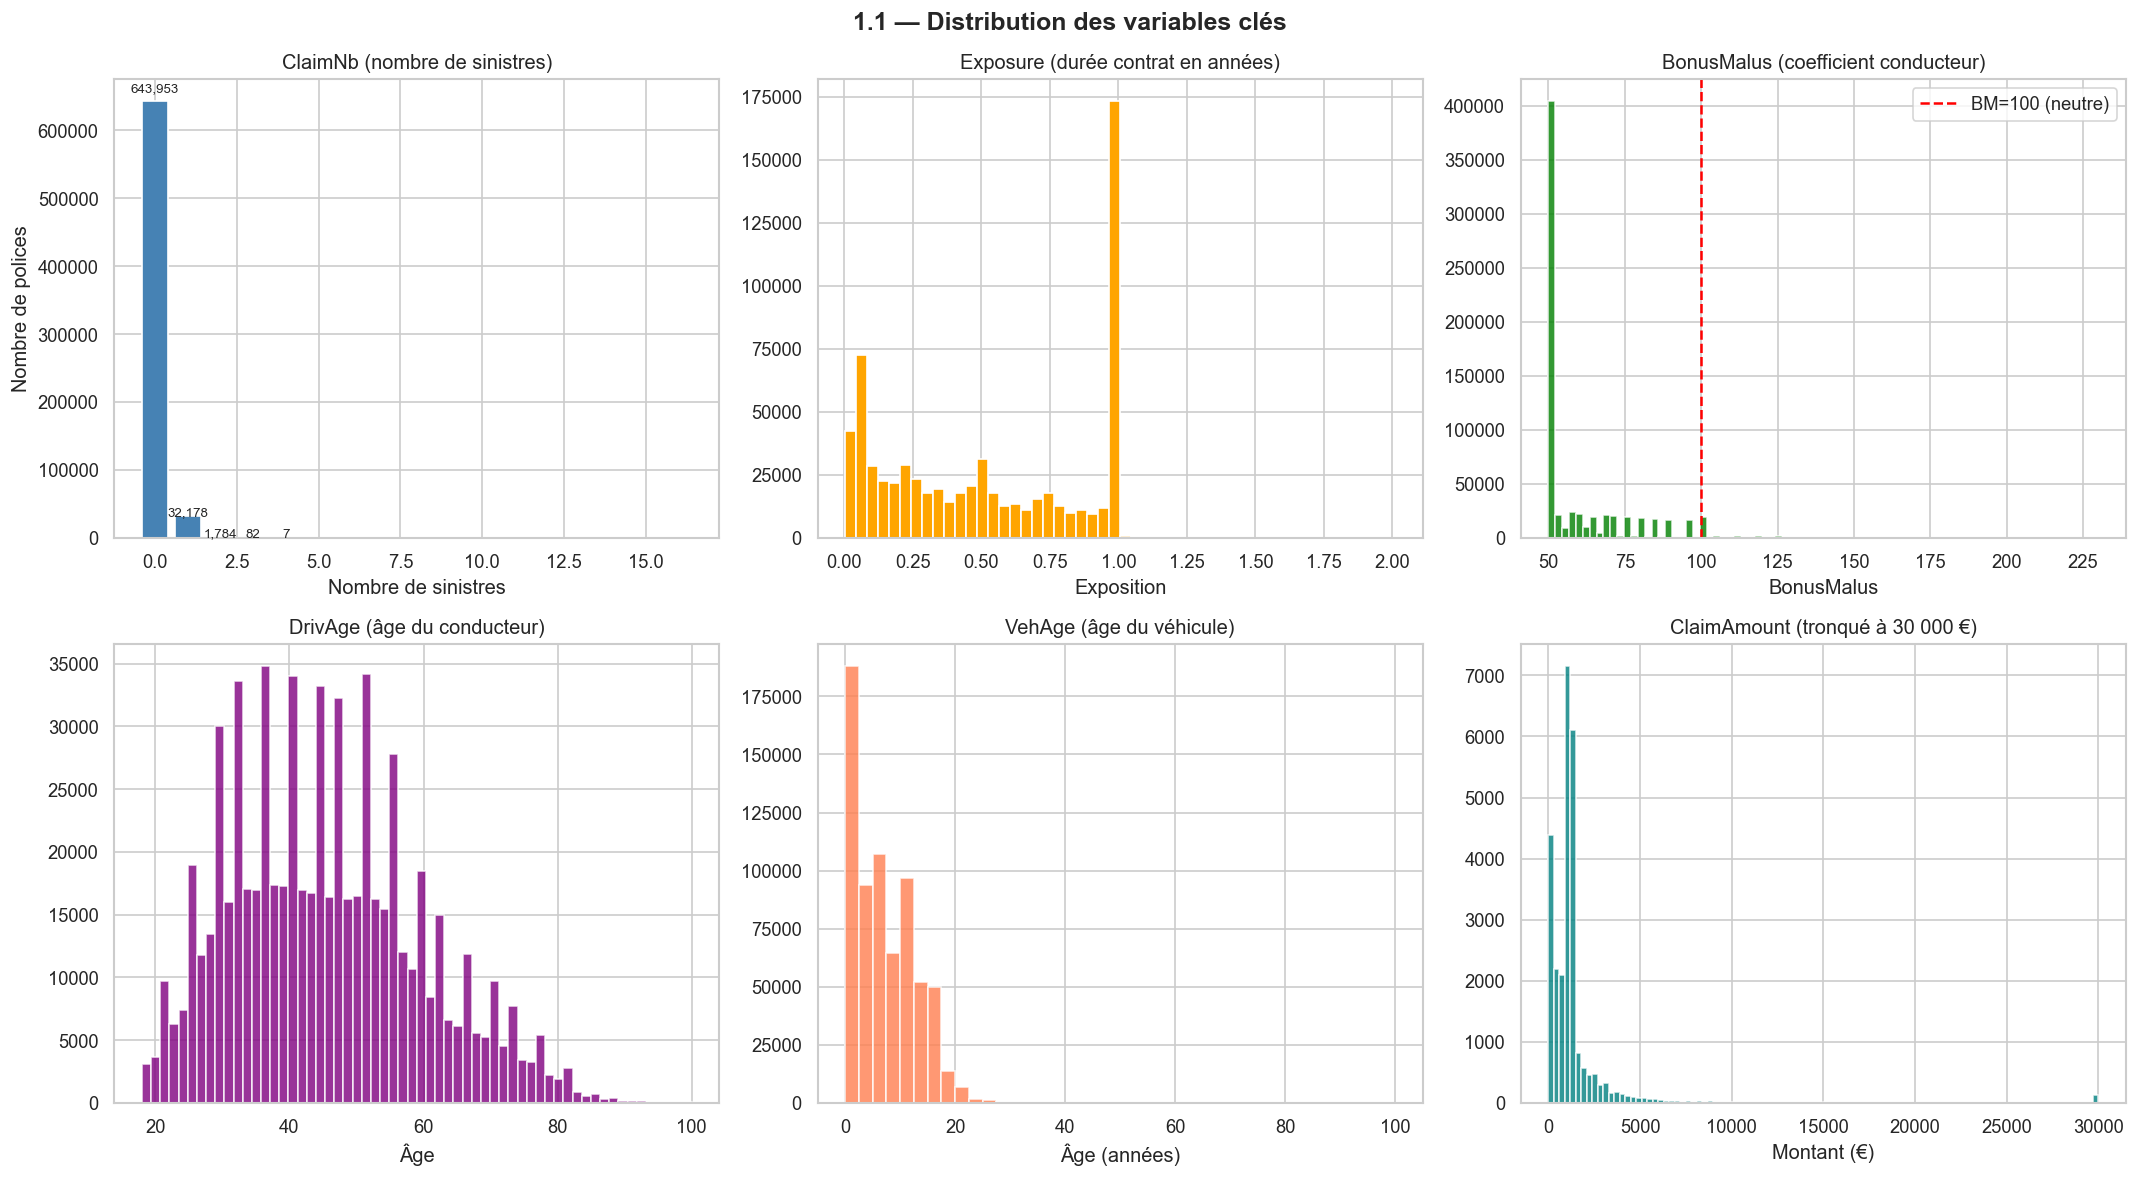

In [19]:

# ── Graphiques de distribution ────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("1.1 — Distribution des variables clés", fontsize=15, fontweight='bold')

# ClaimNb — distribution des sinistres (échelle log pour voir les petites valeurs)
cnb_counts = freq['ClaimNb'].value_counts().sort_index()
axes[0, 0].bar(cnb_counts.index, cnb_counts.values, color='steelblue', edgecolor='white')
axes[0, 0].set_title('ClaimNb (nombre de sinistres)')
axes[0, 0].set_xlabel('Nombre de sinistres')
axes[0, 0].set_ylabel('Nombre de polices')
# Annoter les barres
for x, y in zip(cnb_counts.index[:5], cnb_counts.values[:5]):
    axes[0, 0].text(x, y * 1.02, f'{y:,}', ha='center', fontsize=8)

# Exposure — durée du contrat
freq['Exposure'].hist(bins=50, ax=axes[0, 1], color='orange', edgecolor='white')
axes[0, 1].set_title('Exposure (durée contrat en années)')
axes[0, 1].set_xlabel('Exposition')

# BonusMalus — coefficient conducteur
freq['BonusMalus'].hist(bins=80, ax=axes[0, 2], color='green', edgecolor='white', alpha=0.8)
axes[0, 2].axvline(100, color='red', linestyle='--', linewidth=1.5, label='BM=100 (neutre)')
axes[0, 2].set_title('BonusMalus (coefficient conducteur)')
axes[0, 2].set_xlabel('BonusMalus')
axes[0, 2].legend()

# DrivAge — âge conducteur
freq['DrivAge'].hist(bins=60, ax=axes[1, 0], color='purple', edgecolor='white', alpha=0.8)
axes[1, 0].set_title("DrivAge (âge du conducteur)")
axes[1, 0].set_xlabel('Âge')

# VehAge — âge véhicule
freq['VehAge'].hist(bins=40, ax=axes[1, 1], color='coral', edgecolor='white', alpha=0.8)
axes[1, 1].set_title("VehAge (âge du véhicule)")
axes[1, 1].set_xlabel('Âge (années)')

# ClaimAmount — montant sinistre (tronqué à 30k€ pour la lisibilité)
sev['ClaimAmount'].clip(upper=30_000).hist(bins=100, ax=axes[1, 2], color='teal',
                                            edgecolor='white', alpha=0.8)
axes[1, 2].set_title('ClaimAmount (tronqué à 30 000 €)')
axes[1, 2].set_xlabel('Montant (€)')

plt.tight_layout()
plt.show()

#### INTERPRÉTATION

* La variable **CLaimNb** est très assymétrique à droite. On a une vaste majorité de zero. Ce qui signifie que la plupart des clients ne déclarent aucun sinistre. Ici, due à la forte assymetrie, on peut supposer que la variable **ClaimNb** suit une loi de **Poisson**
* La varible **Exposure**: Les contrats des clients durent en moyenne 6 mois(0.5 ans) et très rare sont ceux qui vont au delà d'un an
* La variable **BonusMalus**: on aussi une  longue queue droite. La grande majorité est autour de 50%
* La variable **ClaimAmount**: L'assymétrie à droite est extrême. Avec un montant minimum de 1 et un maximum de 4075400.56, l'écransante majorité est proche du minimum ($\approx 1^6$ ).peu de sinistres très coûteux 
* La variable **VehAge**: On constate que la majorité des vehicules ont un age entre 0 et 20 ans
* La variable **DrivAge**: distribution large avec pic chez les conducteurs de 30-50 ans.



<h2 style="color: cyan; text-align: center">Taux de sinistralité moyen et proportion de polices sans sinistre</h2>


--- 1.2 Taux de sinistralité et proportions ---

  Taux de sinistralité moyen λ̄ = 0.10070
  Soit environ 1 sinistre tous les 10 ans par assuré

  Polices sans sinistre (ClaimNb=0)  : 94.98%  (643,953)
  Polices avec 1 sinistre             : 4.75%  (32,178)
  Polices avec ≥2 sinistres           : 0.28%  (1,882)


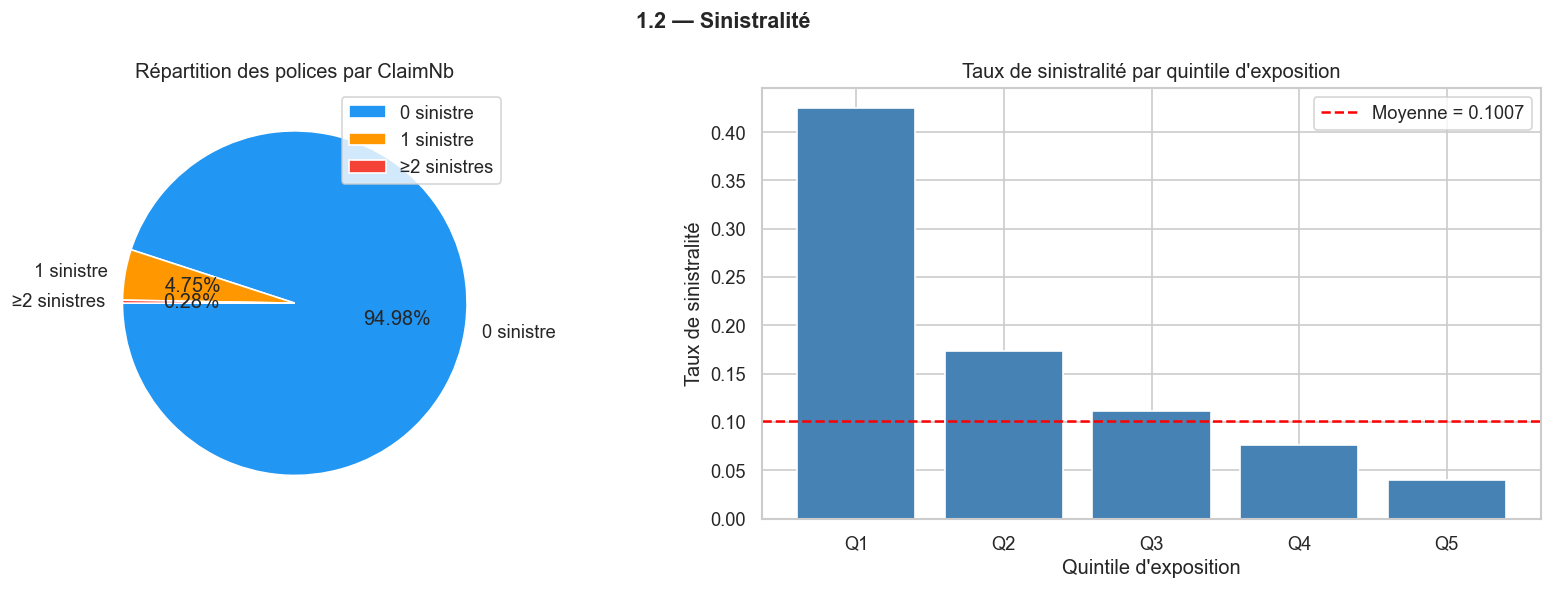

In [20]:
print("\n--- 1.2 Taux de sinistralité et proportions ---")

# C'est le nombre moyen de sinistres par année-contrat
LAMBDA_BAR = freq['ClaimNb'].sum() / freq['Exposure'].sum()
print(f"\n  Taux de sinistralité moyen λ̄ = {LAMBDA_BAR:.5f}")
print(f"  Soit environ 1 sinistre tous les {1/LAMBDA_BAR:.0f} ans par assuré")

# Proportions de polices selon le nombre de sinistres
n_total       = len(freq)
prop_zero     = (freq['ClaimNb'] == 0).mean()
prop_one      = (freq['ClaimNb'] == 1).mean()
prop_two_plus = (freq['ClaimNb'] >= 2).mean()

print(f"\n  Polices sans sinistre (ClaimNb=0)  : {prop_zero:.2%}  ({int(prop_zero*n_total):,})")
print(f"  Polices avec 1 sinistre             : {prop_one:.2%}  ({int(prop_one*n_total):,})")
print(f"  Polices avec ≥2 sinistres           : {prop_two_plus:.2%}  ({int(prop_two_plus*n_total):,})")

# Visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("1.2 — Sinistralité", fontsize=13, fontweight='bold')

# Camembert des proportions
labels = ['0 sinistre', '1 sinistre', '≥2 sinistres']
sizes  = [prop_zero, prop_one, prop_two_plus]
colors = ['#2196F3', '#FF9800', '#F44336']
ax1.pie(sizes, labels=labels, colors=colors, autopct='%1.2f%%', startangle=180)
ax1.set_title('Répartition des polices par ClaimNb')
ax1.legend()

# Taux de sinistralité pondéré par exposition, par quintile d'exposition
freq['expo_quintile'] = pd.qcut(freq['Exposure'], q=5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
taux_par_expo = (freq.groupby('expo_quintile', observed=True)
                 .apply(lambda d: d['ClaimNb'].sum() / d['Exposure'].sum())
                 .reset_index(name='taux'))
ax2.bar(taux_par_expo['expo_quintile'].astype(str), taux_par_expo['taux'],
        color='steelblue', edgecolor='white')
ax2.axhline(LAMBDA_BAR, color='red', linestyle='--', label=f'Moyenne = {LAMBDA_BAR:.4f}')
ax2.set_title("Taux de sinistralité par quintile d'exposition")
ax2.set_xlabel("Quintile d'exposition")
ax2.set_ylabel('Taux de sinistralité')
ax2.legend()

plt.tight_layout()
plt.show()



#### Interprétation

* $\bar{\lambda} \approx$ 0.10  : on a environ 10 sinistres pour 100 années d'exposition(10%).
* Environ 95% des polices n'ont déclaré aucun sinistre sur la période.
* Moins de 1% ont déclaré 2 sinistres ou plus.
Cela confirme que ClaimNb suit une loi de Poisson de faible paramètre.
**Conséquence** : déséquilibre de classes très prononcé
 


<h2 style="color: cyan; text-align: center">Analyse du taux de sinistralité brut par variable catégorielle</h2>

L'idée est de calculer, pour chaque modalité d'une variable catégorielle, le taux de sinistralité brut = somme(ClaimNb) / somme(Exposure). On compare ainsi les modalités entre elles sans tenir compte des interactions.


--- 1.3 Taux de sinistralité brut par variable catégorielle ---

--- Area ---
      n_polices  total_claims     total_expo      taux
Area                                                  
F         17954          1131    8129.234074  0.139127
E        137167          7805   63819.314270  0.122298
D        151596          8428   77120.191692  0.109284
C        191880          9875  104449.003785  0.094544
B         75459          3800   43012.323931  0.088347
A        103957          5063   61969.377712  0.081702

--- VehBrand ---
          n_polices  total_claims    total_expo      taux
VehBrand                                                 
B12          166024          8859  64808.608718  0.136695
B11           13585           721   6887.817279  0.104678
B5            34753          2020  19992.062695  0.101040
B3            53395          2818  28592.876331  0.098556
B13           12178           649   6772.032216  0.095835
B4            25179          1312  13775.496080  0.095242

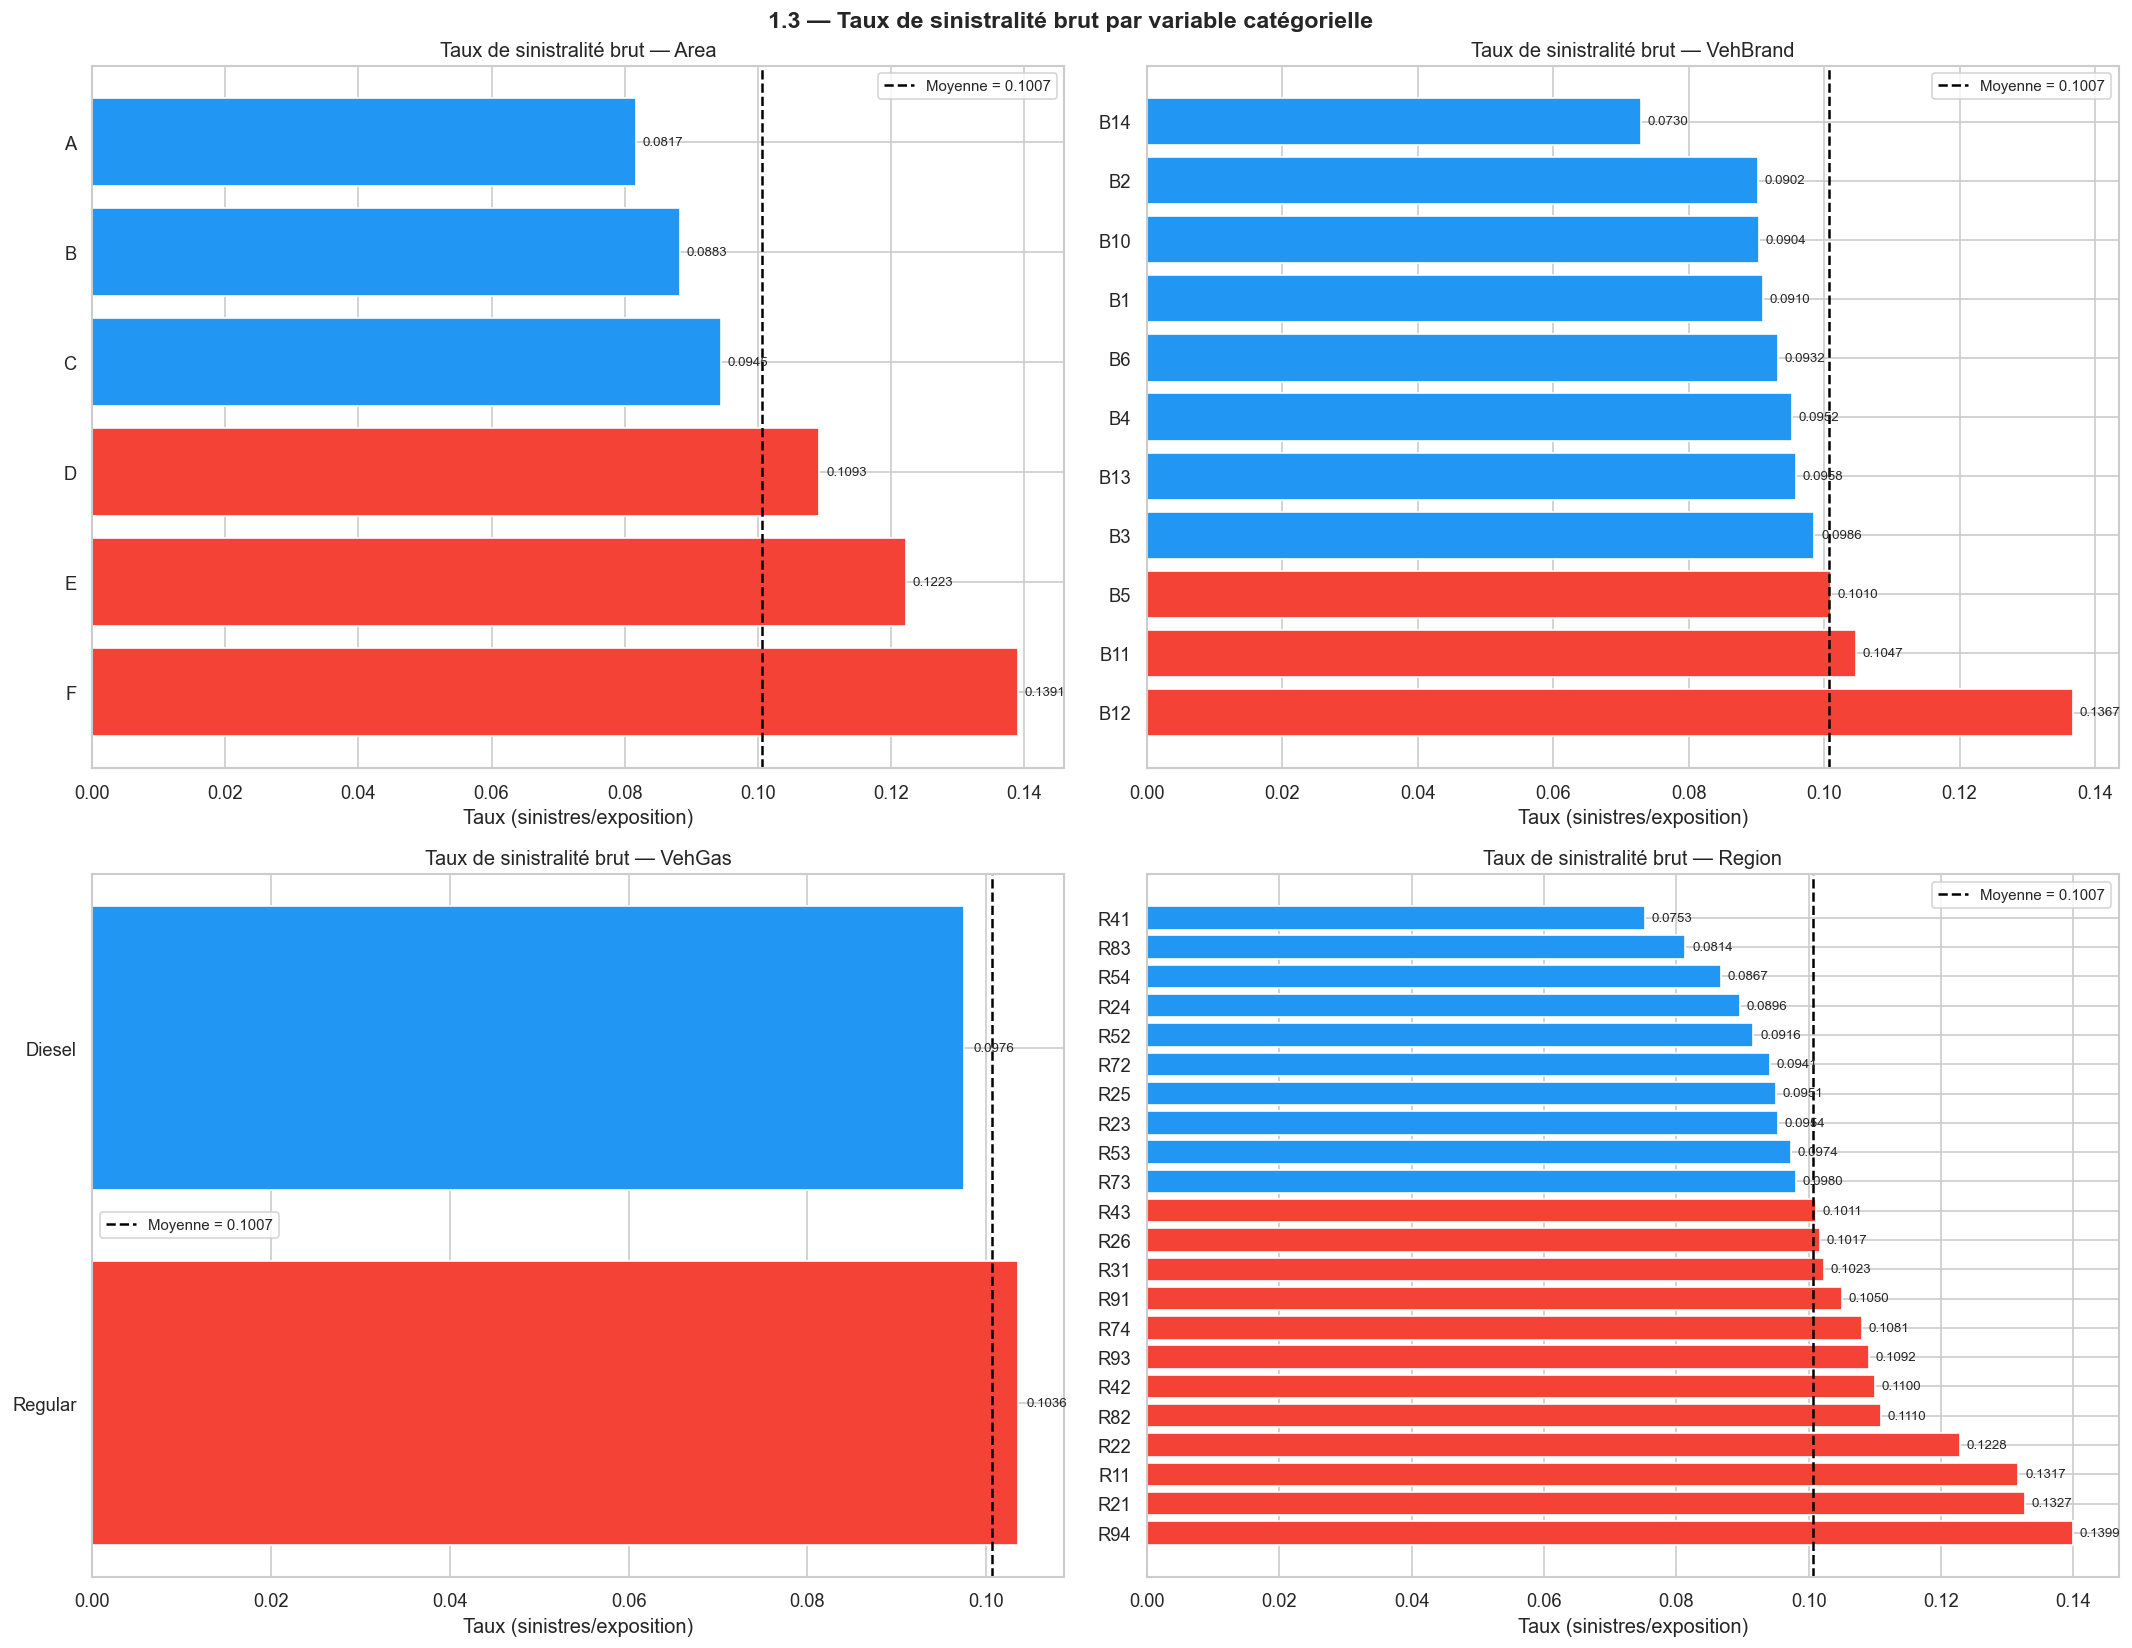

In [21]:

print("\n--- 1.3 Taux de sinistralité brut par variable catégorielle ---")

def taux_brut_par_modalite(df, col):
    """
    Calcule le taux de sinistralité brut par modalité d'une variable catégorielle.
    Taux = ΣClaimNb / ΣExposure (pondéré par l'exposition).
    """
    return (
        df.groupby(col)
        .apply(lambda d: pd.Series({
            'n_polices'   : len(d),
            'total_claims': d['ClaimNb'].sum(),
            'total_expo'  : d['Exposure'].sum(),
            'taux'        : d['ClaimNb'].sum() / d['Exposure'].sum()
        }), include_groups=False)
        .sort_values('taux', ascending=False)
        .reset_index()
    )
def taux_sinistralite_par_modalite(df, col):
    "Calcule le taux brut de sinistralité par modalité d'une variable catégorielle."
    result = df.groupby(col).agg(
        n_polices   = ('IDpol', 'count'),
        total_claims= ('ClaimNb', 'sum'),
        total_expo  = ('Exposure', 'sum')
    ).assign(taux = lambda d: d['total_claims'] / d['total_expo'])
    return result.sort_values('taux', ascending=False)

for col in ['Area', 'VehBrand', 'VehGas', 'Region']:
    res = taux_sinistralite_par_modalite(freq, col)
    print(f'\n--- {col} ---')
    print(res.to_string())

# Calculer pour chaque variable catégorielle
cat_cols = ['Area', 'VehBrand', 'VehGas', 'Region']
taux_dict = {col: taux_brut_par_modalite(freq, col) for col in cat_cols}

# Visualisation — graphiques à barres horizontales
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle("1.3 — Taux de sinistralité brut par variable catégorielle",
             fontsize=14, fontweight='bold')

for ax, col in zip(axes.flatten(), cat_cols):
    df_taux = taux_dict[col]
    # Couleur : rouge si au-dessus de la moyenne, bleu sinon
    colors = ['#F44336' if t > LAMBDA_BAR else '#2196F3' for t in df_taux['taux']]
    bars = ax.barh(df_taux[col].astype(str), df_taux['taux'], color=colors)
    ax.axvline(LAMBDA_BAR, color='black', linestyle='--', linewidth=1.5,
               label=f'Moyenne = {LAMBDA_BAR:.4f}')
    ax.set_title(f'Taux de sinistralité brut — {col}', fontsize=12)
    ax.set_xlabel('Taux (sinistres/exposition)')
    ax.legend(fontsize=9)
    # Annoter les valeurs
    for bar, val in zip(bars, df_taux['taux']):
        ax.text(val + 0.001, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=8)

plt.tight_layout()
plt.show()



#### Interprétation

* **Area** : taux croissant de A (rural) à F (très urbain). Fort effet différenciant(ecart d'environ 2x entre extremes).
* **VehGas** : les véhicules '*Regular*' ont  un taux légèrement plus élevé que  '*Diesel*'.
* **VehBrand** : hétérogénéité notable. Certaines marques (B11, B12) ont un taux bien supérieur.
* **Region** : grande variabilité régionale reflétant les conditions de circulation. On a des regions à fort taux comme *R94*, *R21* ou encore *R11*

Les variables à for effet différentiants sont donc : **Area**  et **Region**

<h2 style="color: cyan; text-align: center">Construction de la matrice de features X</h2>


In [22]:
##copie du travail
data = freq.copy()

### Troncature des valeurs aberrantes

In [23]:

# Troncature AVANT split (sur freq complet)

data['DrivAge']    = data['DrivAge'].clip(18, 90)#on coupe de 18 à 90 ans
data['BonusMalus'] = data['BonusMalus'].clip(50, 300)#on coupe de 50 à 300%

print(f"  DrivAge    — après troncature : [{data['DrivAge'].min()}, {data['DrivAge'].max()}]")
print(f"  BonusMalus — après troncature : [{data['BonusMalus'].min()}, {data['BonusMalus'].max()}]")



  DrivAge    — après troncature : [18, 90]
  BonusMalus — après troncature : [50, 230]


### Transformation logarithmique de Density

In [24]:
# log(Density) pour linéariser l'effet de la densité car la densité de population est très asymétrique (Paris vs zones rurales)
data['LogDensity'] = np.log(data['Density']) 

### préparation des données

In [25]:

# Variable cible fréquence
data['FreqRate'] = data['ClaimNb'] / data['Exposure']   # taux de sinistralité
# Variable binaire pour le split stratifié
data['ClaimNb_bin'] = (data['ClaimNb'] > 0).astype(int)

print(f"\n  Données préparées : {data.shape}")


  Données préparées : (678013, 16)


### Split train/test AVANT l'encodage (prévention du data leakage)

In [26]:
train, test = train_test_split(
    data,
    test_size    = 0.20,
    random_state = RANDOM_STATE,
    stratify     = data['ClaimNb_bin']
)

print(f"\n  Train : {len(train):,} polices ({len(train)/len(data):.0%})")
print(f"  Test  : {len(test):,} polices  ({len(test)/len(data):.0%})")
print(f"\n  Taux sinistralité (ClaimNb≥1) :")
print(f"    Train : {train['ClaimNb_bin'].mean():.4f}")
print(f"    Test  : {test['ClaimNb_bin'].mean():.4f}")
print("  Distributions quasi-identiques : stratification réussie")



  Train : 542,410 polices (80%)
  Test  : 135,603 polices  (20%)

  Taux sinistralité (ClaimNb≥1) :
    Train : 0.0502
    Test  : 0.0502
  Distributions quasi-identiques : stratification réussie


### Target encoding pour Region (sur le train uniquement)

In [27]:
# Calculer le taux de sinistralité PAR RÉGION sur le TRAIN uniquement
region_map = (
    train.groupby('Region')
    .apply(lambda d: d['ClaimNb'].sum() / d['Exposure'].sum(), include_groups=False)
    .to_dict()
)

# Valeur de remplacement pour les régions inconnues dans le test
global_lambda_train = train['ClaimNb'].sum() / train['Exposure'].sum()

train = train.copy()
test  = test.copy()
train['Region_enc'] = train['Region'].map(region_map)
test['Region_enc']  = test['Region'].map(region_map).fillna(global_lambda_train)

print(f"\n  Target encoding Region — {len(region_map)} régions encodées")
print(f"  Taux min/max par région : [{min(region_map.values()):.4f}, {max(region_map.values()):.4f}]")




  Target encoding Region — 22 régions encodées
  Taux min/max par région : [0.0784, 0.1408]


### One-hot encoding pour Area, VehBrand, VehGas

In [28]:
# drop='first' évite la multicolinéarité parfaite (dummy trap)
# handle_unknown='ignore' : modalités inconnues dans le test → colonnes à zéro
cat_ohe_cols = ['Area', 'VehBrand', 'VehGas']
ohe = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')

# FIT uniquement sur le train
ohe.fit(train[cat_ohe_cols])
ohe_feature_names = ohe.get_feature_names_out(cat_ohe_cols)

train_ohe = pd.DataFrame(ohe.transform(train[cat_ohe_cols]),
                          columns=ohe_feature_names, index=train.index)
test_ohe  = pd.DataFrame(ohe.transform(test[cat_ohe_cols]),
                          columns=ohe_feature_names, index=test.index)


### Assemblage final de X_train et X_test

In [29]:

NUM_COLS = ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'LogDensity', 'Region_enc']

X_train = pd.concat([
    train[NUM_COLS].reset_index(drop=True),
    train_ohe.reset_index(drop=True)
], axis=1)

X_test = pd.concat([
    test[NUM_COLS].reset_index(drop=True),
    test_ohe.reset_index(drop=True)
], axis=1)

# Variables cibles et poids (Exposure)
y_train = train['FreqRate'].values
y_test  = test['FreqRate'].values
w_train = train['Exposure'].values
w_test  = test['Exposure'].values

print(f"\n  X_train : {X_train.shape} | X_test : {X_test.shape}")
print(f"  Features : {list(X_train.columns)}")



  X_train : (542410, 22) | X_test : (135603, 22)
  Features : ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'LogDensity', 'Region_enc', 'Area_B', 'Area_C', 'Area_D', 'Area_E', 'Area_F', 'VehBrand_B10', 'VehBrand_B11', 'VehBrand_B12', 'VehBrand_B13', 'VehBrand_B14', 'VehBrand_B2', 'VehBrand_B3', 'VehBrand_B4', 'VehBrand_B5', 'VehBrand_B6', 'VehGas_Regular']


IMPORTANT:

La variable cible ClaimNb est très déséquilibrée : $\sim 93-95 \%$ de zéros.
Un split aléatoire non stratifié pourrait placer la quasi-totalité des sinistres dans le train.

Avec stratification sur ClaimNb_bin, on garantit que la proportion de sinistres est
identique dans le train et le test : les métriques test sont représentatives.

Sans stratification : les modèles apprendraient des distributions légèrement différentes
et le test set ne serait pas représentatif de la réalité opérationnelle.


<h1 style="color: blue; text-align: center">PARTIE 2: MODÈLE DE FRÉQUENCE</h1>

L'objectif est de prédire le taux de sinistralité $\lambda_i=\frac{ClaimNb_i}{Exposure_i}$ pour chaque police i. Nous appliquons et comparons 5 familles de méthodes.

#### FONCTIONS UTILITAIRES — MÉTRIQUES

In [30]:
def rmse_weighted(y_true, y_pred, weights=None):
    """RMSE pondéré par l'exposition."""
    return np.sqrt(mean_squared_error(y_true, y_pred, sample_weight=weights))

def poisson_deviance(y_true, y_pred, weights=None):
    """
    Déviance de Poisson :
        D = 2 * Σ_i [ y_i * log(y_i / ŷ_i) - (y_i - ŷ_i) ]
    Une déviance de 0 correspond à un ajustement parfait.
    Plus petite est la déviance, meilleur est le modèle.
    On ajoute 1e-10 pour éviter log(0) quand y_true = 0.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    # Clip pour éviter les prédictions nulles ou négatives
    y_pred = np.clip(y_pred, 1e-10, None)

    # Terme log : y * log(y/ŷ), nul si y=0
    eps   = 1e-10
    log_t = np.where(y_true > 0, y_true * np.log((y_true + eps) / y_pred), 0.0)
    d     = 2.0 * np.sum(log_t - (y_true - y_pred))

    if weights is not None:
        # Version pondérée
        d = 2.0 * np.sum(weights * (log_t - (y_true - y_pred)))
    return d

# Dictionnaire de stockage des résultats
RESULTS_FREQ = {}   # fréquence
RESULTS_SEV  = {}   # sévérité

<h2 style="color: cyan; text-align: center">Baseline : Prédiction constante</h2>
Le modèle naïf prédit pour toutes les polices la fréquence moyenne du jeu d'entraînement. C'est la référence minimale que tout modèle doit surpasser.


In [31]:

lambda_mean_train = np.average(y_train, weights=w_train)
y_pred_baseline   = np.full(len(y_test), lambda_mean_train)

rmse_baseline = rmse_weighted(y_test, y_pred_baseline, w_test)
dev_baseline  = poisson_deviance(y_test, y_pred_baseline, w_test)

RESULTS_FREQ['Baseline'] = {'RMSE': rmse_baseline, 'Deviance_Poisson': dev_baseline}
print(f"  lambda_barre(train)       = {lambda_mean_train:.6f}")
print(f"  RMSE (test)     = {rmse_baseline:.6f}")
print(f"  Déviance Poisson = {dev_baseline:.2f}") 



  lambda_barre(train)       = 0.100618
  RMSE (test)     = 0.721310
  Déviance Poisson = 44795.51


Ce score sert de référence absolue. Tout modèle doit avoir un RMSE strictement inférieur à celui de la baseline pour apporter une valeur ajoutée.

<h2 style="color: cyan; text-align: center">Régression Ridge et Lasso</h2>


La régression pénalisée nécessite que toutes les features soient à la même. 

échelle: sans normalisation, les features avec de grandes valeurs (ex: Density)

domineraient la pénalité et le gradient.

In [32]:
scaler    = StandardScaler()
X_tr_sc   = scaler.fit_transform(X_train)   # fit sur train uniquement
X_te_sc   = scaler.transform(X_test)

### Définition théorique : Ridge

La **régression Ridge** (*Tikhonov*, 1943 ; *Hoerl & Kennard*, 1970) minimise :
$$ L_{Ridge}(\beta)=\sum_i w_i (y_i-X_i \beta)^2+\alpha \sum_j \beta_j^2$$

L'ajout du terme de régularisation L2 ($\alpha \sum \beta^2$) contracte les coefficients vers zéro sans les annuler. Il résout le problème de multicolinéarité et améliore la généralisation. L'hyperparamètre $\alpha$ contrôle l'intensité de la pénalisation.


In [33]:
alphas_grid = np.logspace(-4, 5, 60)
ridge = RidgeCV(alphas=alphas_grid, cv=5)
ridge.fit(X_tr_sc, y_train, sample_weight=w_train)

y_pred_ridge = np.clip(ridge.predict(X_te_sc), 1e-10, None)
rmse_ridge   = rmse_weighted(y_test, y_pred_ridge, w_test)
dev_ridge    = poisson_deviance(y_test, y_pred_ridge, w_test)

RESULTS_FREQ['Ridge'] = {'RMSE': rmse_ridge, 'Deviance_Poisson': dev_ridge}
print(f"\n  Ridge — alpha optimal = {ridge.alpha_:.4f}")
print(f"    RMSE      = {rmse_ridge:.6f}")
print(f"    Déviance  = {dev_ridge:.2f}")


  Ridge — alpha optimal = 1039.7984
    RMSE      = 0.719769
    Déviance  = 43519.70


### Définition théorique : Lasso

Le **Lasso** (*Tibshirani*, 1996) utilise une pénalité L1 :
$$L_{Lasso}(\beta)=\sum_i w_i (y_i-X_i \beta)^2+\alpha \sum_j | \beta_j | $$
Contrairement à Ridge, la pénalité L1 peut annuler exactement certains coefficients (sélection de variables implicite). Cela permet d'identifier quelles features sont vraiment utiles.



In [34]:
lasso = LassoCV(alphas=alphas_grid, cv=5, max_iter=10_000, random_state=RANDOM_STATE)
lasso.fit(X_tr_sc, y_train, sample_weight=w_train)

y_pred_lasso = np.clip(lasso.predict(X_te_sc), 1e-10, None)
rmse_lasso   = rmse_weighted(y_test, y_pred_lasso, w_test)
dev_lasso    = poisson_deviance(y_test, y_pred_lasso, w_test)

RESULTS_FREQ['Lasso'] = {'RMSE': rmse_lasso, 'Deviance_Poisson': dev_lasso}
print(f"\n  Lasso — alpha optimal = {lasso.alpha_:.6f}")
print(f"    RMSE      = {rmse_lasso:.6f}")
print(f"    Déviance  = {dev_lasso:.2f}")

# Coefficients non nuls
nonzero = (lasso.coef_ != 0).sum()
zero    = (lasso.coef_ == 0).sum()
print(f"    Variables retenues  : {nonzero} / {len(lasso.coef_)}")
print(f"    Variables éliminées : {zero}")
elim = X_train.columns[lasso.coef_ == 0].tolist()
if elim:
    print(f"    Éliminées : {elim}")


  Lasso — alpha optimal = 0.000202
    RMSE      = 0.719771
    Déviance  = 43487.71
    Variables retenues  : 20 / 22
    Variables éliminées : 2
    Éliminées : ['Area_B', 'Area_F']


### Chemin de régularisation Lasso

Montre pour quel $\alpha$ chaque variable entre dans le modèle (ou en sort). Les variables qui résistent le plus longtemps avant d'être annulées sont les plus importantes.


  Tracé du chemin de régularisation Lasso...


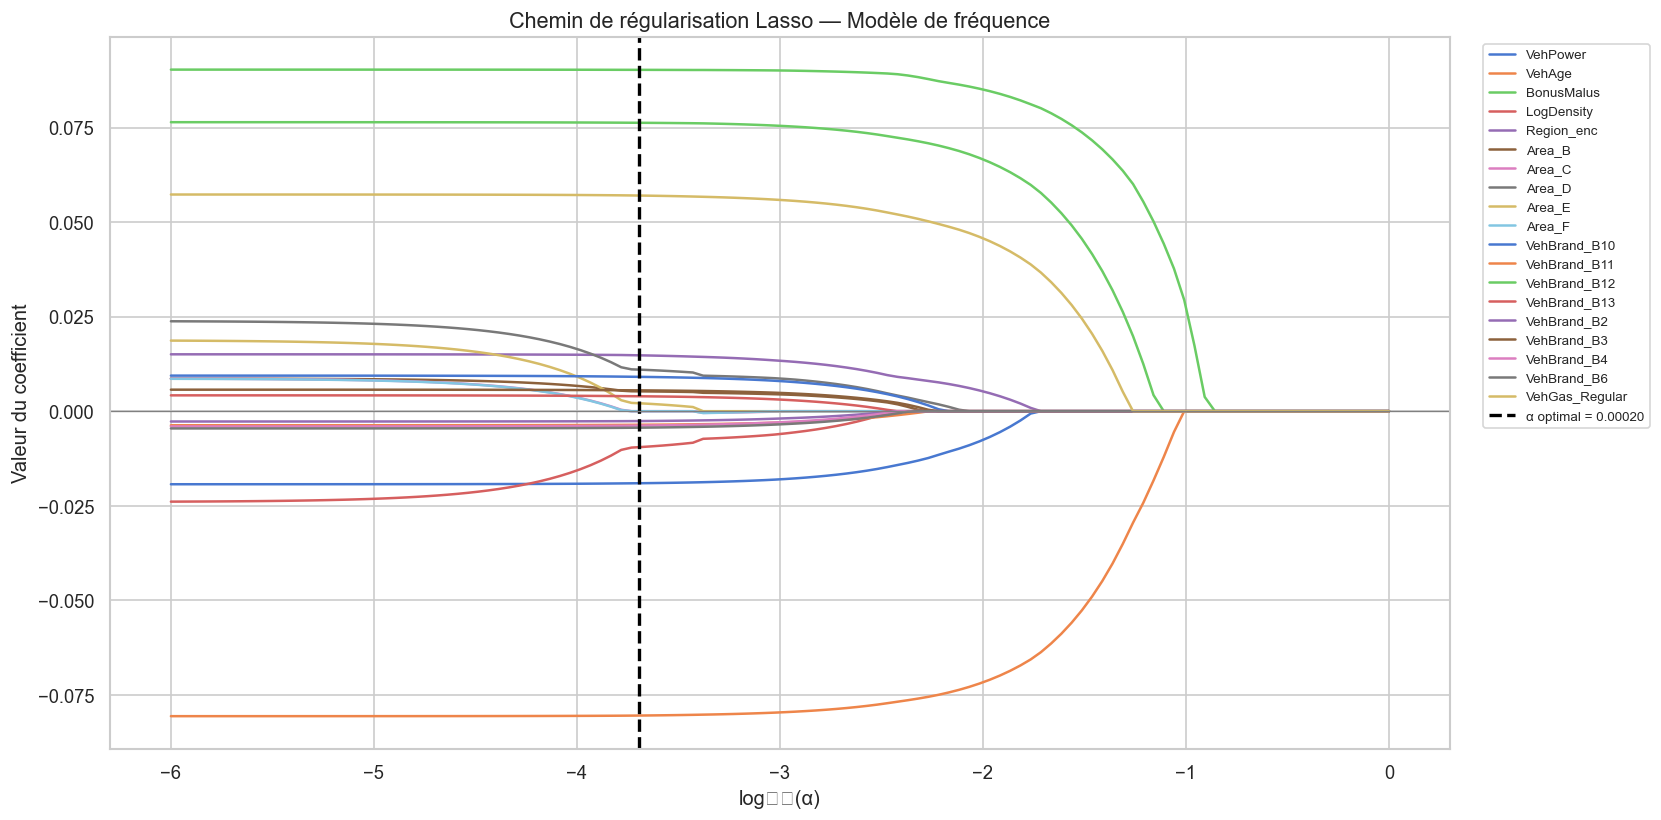

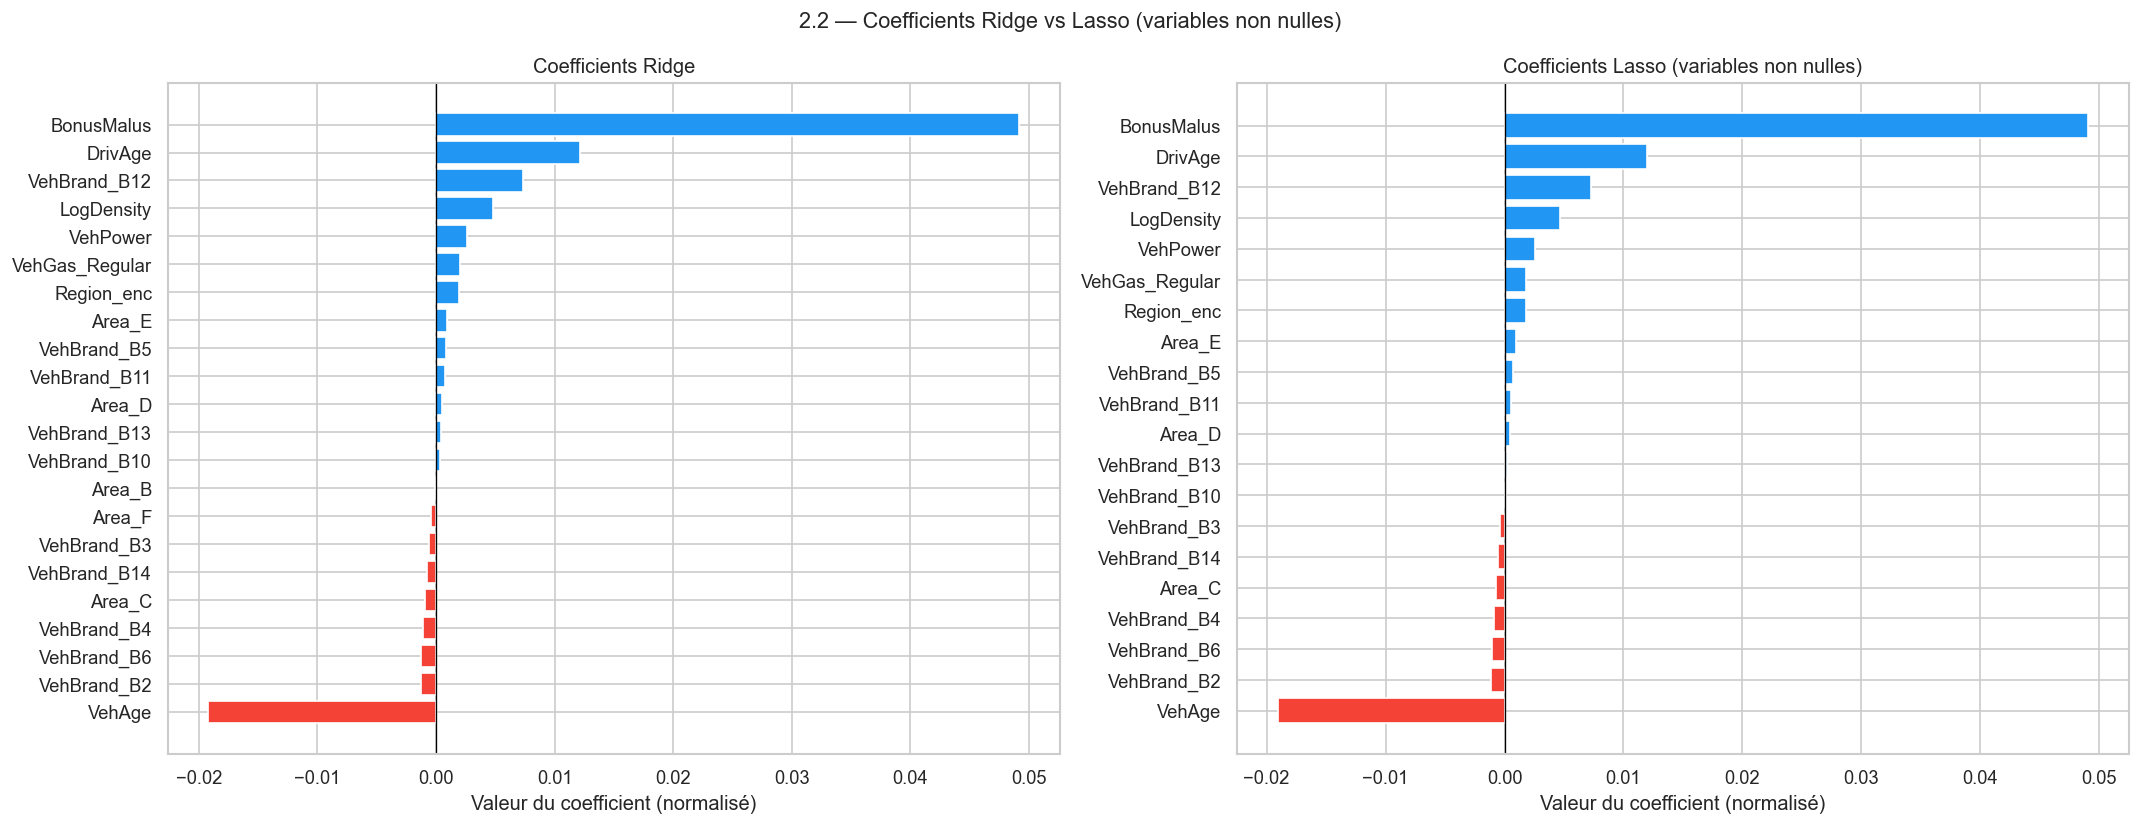

In [35]:
print("\n  Tracé du chemin de régularisation Lasso...")
alphas_path, coefs_path, _ = lasso_path(
    X_tr_sc, y_train,
    alphas  = np.logspace(-6, 0, 120),
    eps     = 1e-4
)

# On ne trace que les variables avec un coefficient max > 0.002 (lisibilité)
significant = np.abs(coefs_path).max(axis=1) > 0.002
labels_path = X_train.columns[significant]

fig, ax = plt.subplots(figsize=(14, 7))
for i, (sig, label) in enumerate(zip(significant, X_train.columns)):
    if sig:
        ax.plot(np.log10(alphas_path), coefs_path[i], linewidth=1.5, label=label)

ax.axvline(np.log10(lasso.alpha_), color='black', linestyle='--', linewidth=2,
           label=f'α optimal = {lasso.alpha_:.5f}')
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xlabel('log₁₀(α)', fontsize=12)
ax.set_ylabel('Valeur du coefficient', fontsize=12)
ax.set_title('Chemin de régularisation Lasso — Modèle de fréquence', fontsize=13)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

#  Visualisation des coefficients Lasso et Ridge
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("2.2 — Coefficients Ridge vs Lasso (variables non nulles)", fontsize=13)

coef_ridge = pd.Series(ridge.coef_, index=X_train.columns).sort_values()
coef_lasso = pd.Series(lasso.coef_, index=X_train.columns)
coef_lasso = coef_lasso[coef_lasso != 0].sort_values()

colors_r = ['#F44336' if c < 0 else '#2196F3' for c in coef_ridge]
axes[0].barh(coef_ridge.index, coef_ridge.values, color=colors_r)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Coefficients Ridge')
axes[0].set_xlabel('Valeur du coefficient (normalisé)')

colors_l = ['#F44336' if c < 0 else '#2196F3' for c in coef_lasso]
axes[1].barh(coef_lasso.index, coef_lasso.values, color=colors_l)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Coefficients Lasso (variables non nulles)')
axes[1].set_xlabel('Valeur du coefficient (normalisé)')

plt.tight_layout()
plt.show()

#### Interprétations

*  On observe visuellement que les variables ne diminuent pas toutes de façon lisse : elles "meurent" (atteignent $0$) les unes après les autres à des seuils d'énergies différents. C'est la propriété géométrique de la norme $L_1$ (pénalité sur la somme des valeurs absolues), qui crée des solutions creuses (sparse models)
* Le choix de l'$\alpha$ optimal (ligne pointillée noire): La ligne pointillée indique la valeur exacte retenue par la validation croisée. C'est le compromis idéal (biais-variance) : Assez à gauche pour conserver le signal prédictif important, et assez à droite pour avoir éliminé le bruit de fond et les variables superflues.
* **BonusMalus** est le coefficient le plus fort (résiste longtemps avant d'être annulé).
* Les modalités OHE de VehBrand les moins représentées sont annulées en premier.

<h2 style="color: cyan; text-align: center">Arbre de décision CART</h2>

**CART** (*Classification And Regression Trees*, *Breiman et al.*, 1984) construit un arbre binaire par partitionnement récursif. À chaque nœud, on choisit la feature j et le seuil s qui minimisent l'impureté (variance résiduelle pour la régression) :

$$Gain(j,s)=Var(y_{noeud})-\left[ \frac{n_{gauche}}{n}*Var(y_{gauche})+\frac{n_{droite}}{n}*Var(y_{droite})\right]$$


L'arbre est élagué par la profondeur maximale (max_depth) et le nombre minimal d'échantillons par feuille. C'est un modèle interprétable mais susceptible au surapprentissage si la profondeur est trop grande.



  depth |   RMSE_train |  RMSE_test |   Dev_test | Statut
  ------------------------------------------------------------
      3 |     0.746988 |   0.717035 |   42348.58 | ✓ OK
      5 |     0.745920 |   0.715791 |   41873.62 | ✓ OK
      8 |     0.744326 |   0.714412 |   41513.30 | ✓ OK
     15 |     0.742735 |   0.715270 |   43751.94 | ✓ OK


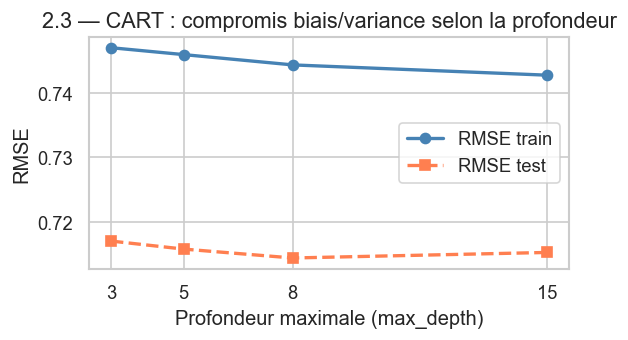

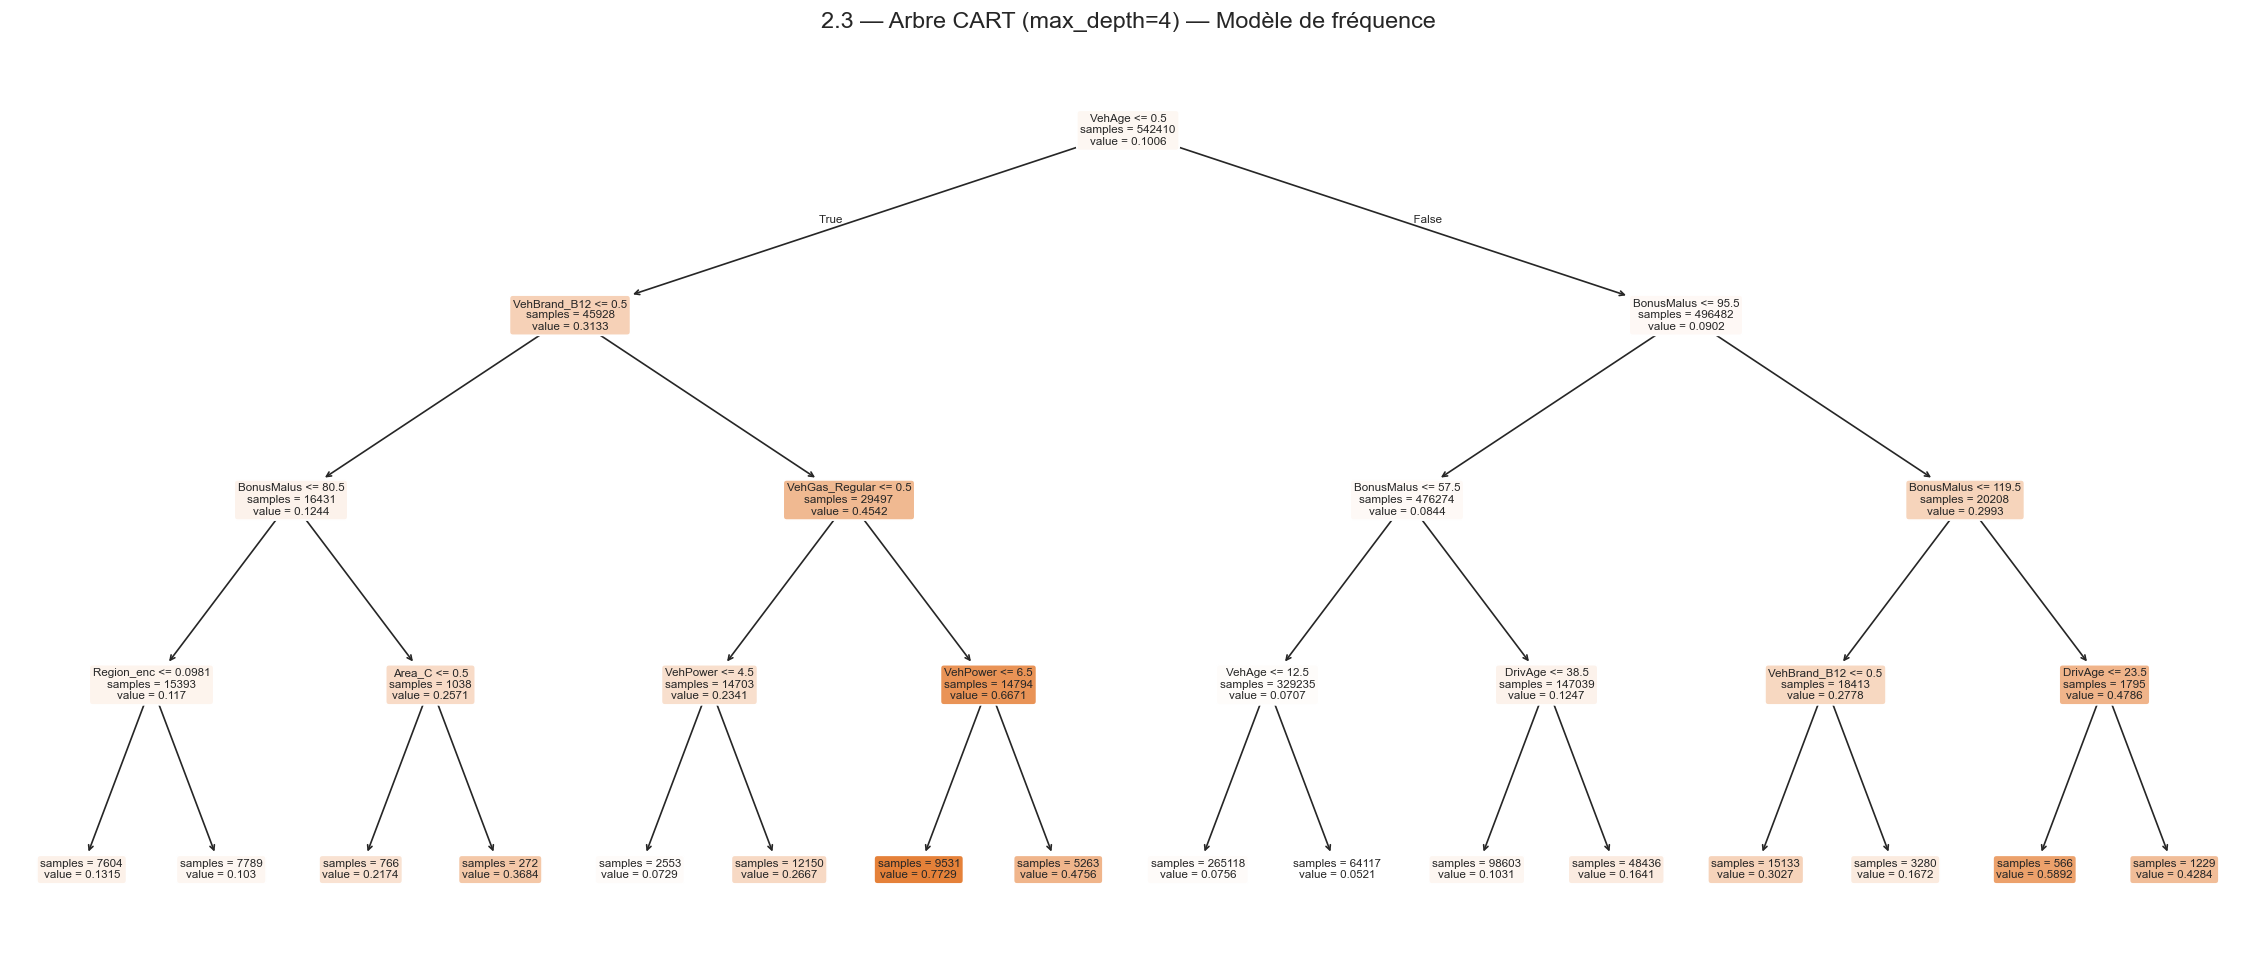


  Meilleure profondeur : 8 (RMSE_test = 0.714412)


In [36]:
depths = [3, 5, 8, 15]
results_cart = {}

print(f"\n  {'depth':>5} | {'RMSE_train':>12} | {'RMSE_test':>10} | {'Dev_test':>10} | {'Statut'}")
print("  " + "-" * 60)

for d in depths:
    cart = DecisionTreeRegressor(
        max_depth       = d,
        min_samples_leaf= 200,   # évite les feuilles trop petites (surapprentissage)
        random_state    = RANDOM_STATE
    )
    cart.fit(X_train, y_train, sample_weight=w_train)

    y_tr = np.clip(cart.predict(X_train), 1e-10, None)
    y_te = np.clip(cart.predict(X_test),  1e-10, None)

    r_tr  = rmse_weighted(y_train, y_tr, w_train)
    r_te  = rmse_weighted(y_test,  y_te, w_test)
    d_te  = poisson_deviance(y_test, y_te, w_test)
    overfit = "⚠ surapprentissage" if r_te > r_tr * 1.05 else "✓ OK"

    results_cart[d] = {'RMSE_train': r_tr, 'RMSE_test': r_te, 'Dev_test': d_te}
    print(f"  {d:>5} | {r_tr:>12.6f} | {r_te:>10.6f} | {d_te:>10.2f} | {overfit}")

# Courbe biais/variance
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(depths, [results_cart[d]['RMSE_train'] for d in depths],
        'o-', color='steelblue', label='RMSE train', linewidth=2)
ax.plot(depths, [results_cart[d]['RMSE_test'] for d in depths],
        's--', color='coral', label='RMSE test', linewidth=2)
ax.set_xlabel('Profondeur maximale (max_depth)', fontsize=12)
ax.set_ylabel('RMSE', fontsize=12)
ax.set_title('2.3 — CART : compromis biais/variance selon la profondeur', fontsize=13)
ax.legend()
ax.set_xticks(depths)
plt.tight_layout()
plt.show()

#  Visualisation de l'arbre à depth=4
cart4 = DecisionTreeRegressor(max_depth=4, min_samples_leaf=200, random_state=RANDOM_STATE)
cart4.fit(X_train, y_train, sample_weight=w_train)

fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(
    cart4,
    feature_names = list(X_train.columns),
    filled        = True,
    rounded       = True,
    fontsize      = 7,
    ax            = ax,
    impurity      = False,   # on ne montre que les valeurs prédites
    precision     = 4
)
plt.title("2.3 — Arbre CART (max_depth=4) — Modèle de fréquence", fontsize=14)
plt.show()

# Meilleur CART pour le tableau comparatif
best_depth = min(results_cart, key=lambda d: results_cart[d]['RMSE_test'])
cart_best  = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=200,
                                    random_state=RANDOM_STATE)
cart_best.fit(X_train, y_train, sample_weight=w_train)
y_pred_cart = np.clip(cart_best.predict(X_test), 1e-10, None)

RESULTS_FREQ[f'CART (depth={best_depth})'] = {
    'RMSE'              : results_cart[best_depth]['RMSE_test'],
    'Deviance_Poisson'  : results_cart[best_depth]['Dev_test']
}
print(f"\n  Meilleure profondeur : {best_depth} (RMSE_test = {results_cart[best_depth]['RMSE_test']:.6f})")


#### Interprétation

*  Dès que la profondeur atteint $8$ , la RMSE_train s'effondre (l'arbre s'ajuste parfaitement aux données d'apprentissage), tandis que la RMSE_test remonte ou stagne, déclenchant l'alerte " surapprentissage".Le coude se situe à $\text{max\_depth} = 8$

* En tarification, un arbre trop profond ($\text{max\_depth} = 15$) diviserait le portefeuille en milliers de micro-niches contenant très peu d'assurés. Si un sinistre grave survient par pur hasard dans l'une de ces micro-niches, l'arbre lui attribuerait une prime pure astronomique l'année suivante.

* **l'Arbre CART de Fréquence ($\text{max\_depth}=4$)**: Le grand graphique de la structure de l'arbre permet de lire mot à mot la politique de segmentation du risque de l'algorithme.La toute première variable choisie pour scinder le portefeuille est le BonusMalus. C'est le descripteur le plus puissant de tout ton modèle.

* Chaque feuille affiche une ligne value = X.XXXX. Dans un modèle de fréquence ajusté avec une fonction de perte Poisson et le poids Exposure, cette valeur représente le taux de sinistralité annuel moyen prédit ($\hat{\lambda}$) pour les assurés qui atterrissent dans cette feuille.

<h2 style="color: cyan; text-align: center">Forêt aléatoire</h2>

La **forêt aléatoire** (*Breiman*, 2001) est un ensemble de B arbres de décision entraînés en parallèle sur des sous-échantillons bootstrap. Pour chaque arbre, à chaque nœud, seulement m features ($m \approx \sqrt{p}$) sont considérées pour le split (sous-espace aléatoire). La prédiction finale est la moyenne des prédictions de tous les arbres :

$$\hat{y}_{RF}=\frac{1}{B}*\sum_{b=1}^B T_b(x)$$

Les deux sources d'aléa (bootstrap + sous-espace) décorrèlent les arbres, ce qui réduit la variance sans augmenter le biais. L'**erreur OOB** (Out-Of-Bag) est une estimation non biaisée de l'erreur de généralisation, calculée sur les échantillons non tirés dans le bootstrap.



  Calibration du nombre d'arbres via l'erreur OOB...
    n_trees= 20 — OOB R² = 0.00245
    n_trees= 40 — OOB R² = 0.00245
    n_trees= 60 — OOB R² = 0.00248
    n_trees= 80 — OOB R² = 0.00246
    n_trees=100 — OOB R² = 0.00245
    n_trees=120 — OOB R² = 0.00244
    n_trees=140 — OOB R² = 0.00241


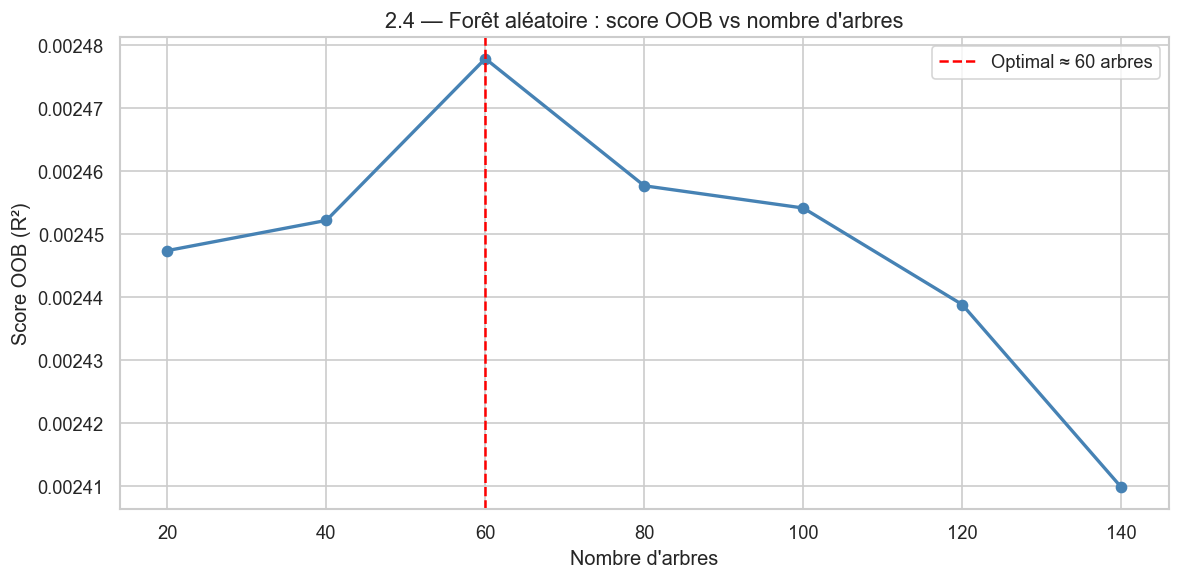


  RF final (160 arbres)
    OOB R²   = 0.00241
    RMSE     = 0.715075
    Déviance = 41350.48


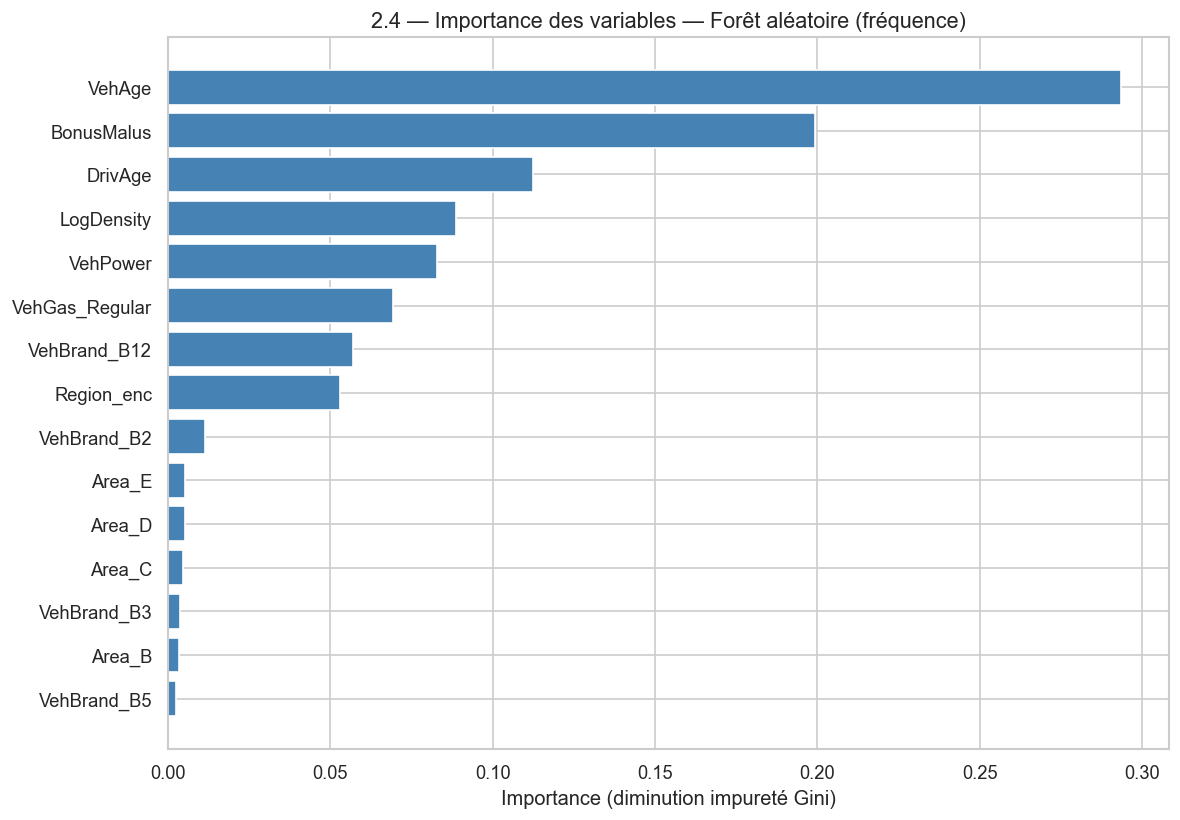


  Top 10 variables les plus importantes (RF) :
    VehAge               0.29350
    BonusMalus           0.19922
    DrivAge              0.11233
    LogDensity           0.08882
    VehPower             0.08284
    VehGas_Regular       0.06935
    VehBrand_B12         0.05689
    Region_enc           0.05288
    VehBrand_B2          0.01140
    Area_E               0.00533

  Comparaison RF vs Lasso (top 10) :
    Variables communes dans le top 10 : 9 — {'VehBrand_B2', 'VehAge', 'VehPower', 'Region_enc', 'VehBrand_B12', 'VehGas_Regular', 'LogDensity', 'BonusMalus', 'DrivAge'}


In [37]:
print("\n  Calibration du nombre d'arbres via l'erreur OOB...")
n_trees_list = list(range(20, 141, 20))
oob_scores   = []

for n in n_trees_list:
    rf_tmp = RandomForestRegressor(
        n_estimators     = n,
        max_features     = 'sqrt',    # √p features par nœud (règle standard)
        min_samples_leaf = 100,       # régularisation
        oob_score        = True,
        random_state     = RANDOM_STATE,
        n_jobs           = -1         # utiliser tous les cœurs CPU
    )
    rf_tmp.fit(X_train, y_train, sample_weight=w_train)
    oob_scores.append(rf_tmp.oob_score_)
    print(f"    n_trees={n:3d} — OOB R² = {rf_tmp.oob_score_:.5f}")

# Graphe OOB vs nombre d'arbres
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_trees_list, oob_scores, 'o-', color='steelblue', linewidth=2)
ax.set_xlabel("Nombre d'arbres", fontsize=12)
ax.set_ylabel('Score OOB (R²)', fontsize=12)
ax.set_title("2.4 — Forêt aléatoire : score OOB vs nombre d'arbres", fontsize=13)
ax.axvline(n_trees_list[np.argmax(oob_scores)], color='red', linestyle='--',
           label=f"Optimal ≈ {n_trees_list[np.argmax(oob_scores)]} arbres")
ax.legend()
plt.tight_layout()
plt.show()

#  Modèle final
N_TREES_RF = 160   # plateau généralement atteint vers 100-160 arbres
rf_freq = RandomForestRegressor(
    n_estimators     = N_TREES_RF,
    max_features     = 'sqrt',
    min_samples_leaf = 100,
    oob_score        = True,
    random_state     = RANDOM_STATE,
    n_jobs           = -1
)
rf_freq.fit(X_train, y_train, sample_weight=w_train)

y_pred_rf    = np.clip(rf_freq.predict(X_test), 1e-10, None)
rmse_rf      = rmse_weighted(y_test, y_pred_rf, w_test)
dev_rf       = poisson_deviance(y_test, y_pred_rf, w_test)

RESULTS_FREQ['Random Forest'] = {'RMSE': rmse_rf, 'Deviance_Poisson': dev_rf}
print(f"\n  RF final ({N_TREES_RF} arbres)")
print(f"    OOB R²   = {rf_freq.oob_score_:.5f}")
print(f"    RMSE     = {rmse_rf:.6f}")
print(f"    Déviance = {dev_rf:.2f}")

#  Importance des variables (Gini)
imp_rf_freq = pd.Series(rf_freq.feature_importances_,
                         index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
top15 = imp_rf_freq.head(15)
ax.barh(top15.index, top15.values, color='steelblue')
ax.invert_yaxis()
ax.set_title("2.4 — Importance des variables — Forêt aléatoire (fréquence)", fontsize=13)
ax.set_xlabel('Importance (diminution impureté Gini)')
plt.tight_layout()
plt.show()

print("\n  Top 10 variables les plus importantes (RF) :")
for feat, imp in imp_rf_freq.head(10).items():
    print(f"    {feat:<20} {imp:.5f}")

#  Comparaison RF vs Lasso 
# On compare l'importance RF aux coefficients Lasso (en valeur absolue)
print("\n  Comparaison RF vs Lasso (top 10) :")
top_rf    = imp_rf_freq.head(10).index.tolist()
coef_abs  = pd.Series(np.abs(lasso.coef_), index=X_train.columns).sort_values(ascending=False)
top_lasso = coef_abs.head(10).index.tolist()
common    = set(top_rf) & set(top_lasso)
print(f"    Variables communes dans le top 10 : {len(common)} — {common}")




#### Interprétation

* Le score d'importance de **VehAge** et de  **BonusMalus**  écrase littéralement tous les autres prédicteurs. La forêt aléatoire confirme mathématiquement que le comportement passé est le miroir des risques futurs : un conducteur qui accumule les sinistres (fort malus) présente une probabilité intrinsèque de provoquer un nouvel accident bien plus élevée qu'un conducteur au bonus maximal.

* La densité de population (**LogDensity**) et la classification de la zone géographique (**Area**) s'octroient les prochaines places: En zone urbaine ultra-dense (LogDensity élevé, zones Area_E ou Area_F), la concentration de véhicules au kilomètre carré démultiplie le risque d'accrochages, de collisions aux carrefours ou d'accidents impliquant des piétons. Le modèle identifie à juste titre que l'environnement où circule le véhicule est le second pilier de la construction du tarif.

<h2 style="color: cyan; text-align: center">Gradient Boosting</h2>

Le <b>Le Gradient Boosting</b> est aujourd'hui l'une des techniques les plus performantes pour traiter des données structurées, popularisée par des librairies comme <b>XGBoost</b>

Le principe clé du Gradient Boosting est l'itération : on cherche à améliorer la prédiction globale en entraînant séquentiellement de nouveaux modèles sur les résidus (les erreurs) des modèles précédents.</br>
Contrairement à d’autres méthodes qui cherchent à trouver le meilleur modèle unique tout de suite, le Gradient Boosting construit sa solution couche par couche. Voici par étape comment se déroule le processus logique :
* On commence par un modèle simple (souvent très basique) qui fait une première prédiction. Naturellement, celle-ci est imparfaite et laisse un écart avec la réalité : c’est ce qu’on appelle le résidu.

* Plutôt que de jeter ce premier modèle, on en entraîne un second. Mais l’objectif de ce second modèle n’est pas de prédire la cible originale, mais de prédire l’erreur commise par le premier. Il agit comme un correcteur.

* Le modèle « amélioré » n’est pas simplement le second modèle, mais la somme du premier modèle et du correcteur.</br>

Dans des algorithmes comme <b>XGBoost</b>, ce cycle est répété des centaines, voire des milliers de fois. À chaque étape, on ajoute un nouveau "correcteur" qui se focalise sur les erreurs laissées par l'ensemble des modèles précédents.

Mathématiquement, on dit que c’est un modèle additif : la prédiction finale est la somme de toutes les petites corrections apportées successivement. L'intuition derrière cette répétition est que si chaque nouveau modèle parvient à capturer une partie de l'erreur restante, le résidu global va progressivement converger vers 0


Pour éviter le surapprentissage (overfitting), le gradient boosting adopte une stratégie contre-intuitive : il utilise volontairement des modèles rudimentaires, appelés <b><i>Weak Learners</i></b>.

Plutôt que d’utiliser un arbre de décision très complexe et profond capable de tout mémoriser, on contraint fortement la complexité des correcteurs (par exemple, en limitant la profondeur des arbres). L'objectif n'est pas que ce correcteur résolve tout le problème d’un coup, mais qu'il capture juste la tendance générale de l'erreur, sans apprendre le bruit spécifique aux données.

Pour renforcer cette prudence, on utilise un second mécanisme de sécurité : le <i><b>learning rate</b></i> (noté<b> $\eta$</b>).

Au lieu d'ajouter la totalité de la correction prédite par le Weak Learner, on n'en ajoute qu'une fraction (par exemple $\eta$ = 0.1). Cela force l'algorithme à faire de nombreux "petits pas" prudents vers la solution, plutôt que quelques grands sauts risqués qui pourraient déstabiliser le modèle global.

Ce que les <i>Weak Learners</i> essaient de prédire et de corriger à chaque étape correspond en réalité au <b> gradient de la fonction de coût</b>(D'où le terme Gradient Boosting)
<div style="display: flex; justify-content: center;"> <img src="XGboost1.JPG" widht="400" height="400" alt="smote" > </div>


  GridSearchCV 5-fold pour la sélection d'hyperparamètres...
  Meilleurs hyperparamètres : {'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 200}
  RMSE CV (train)          : 0.744767

  HGB final
    Itérations effectives : 135
    RMSE (test)          : 0.714307
    Déviance             : 41167.71


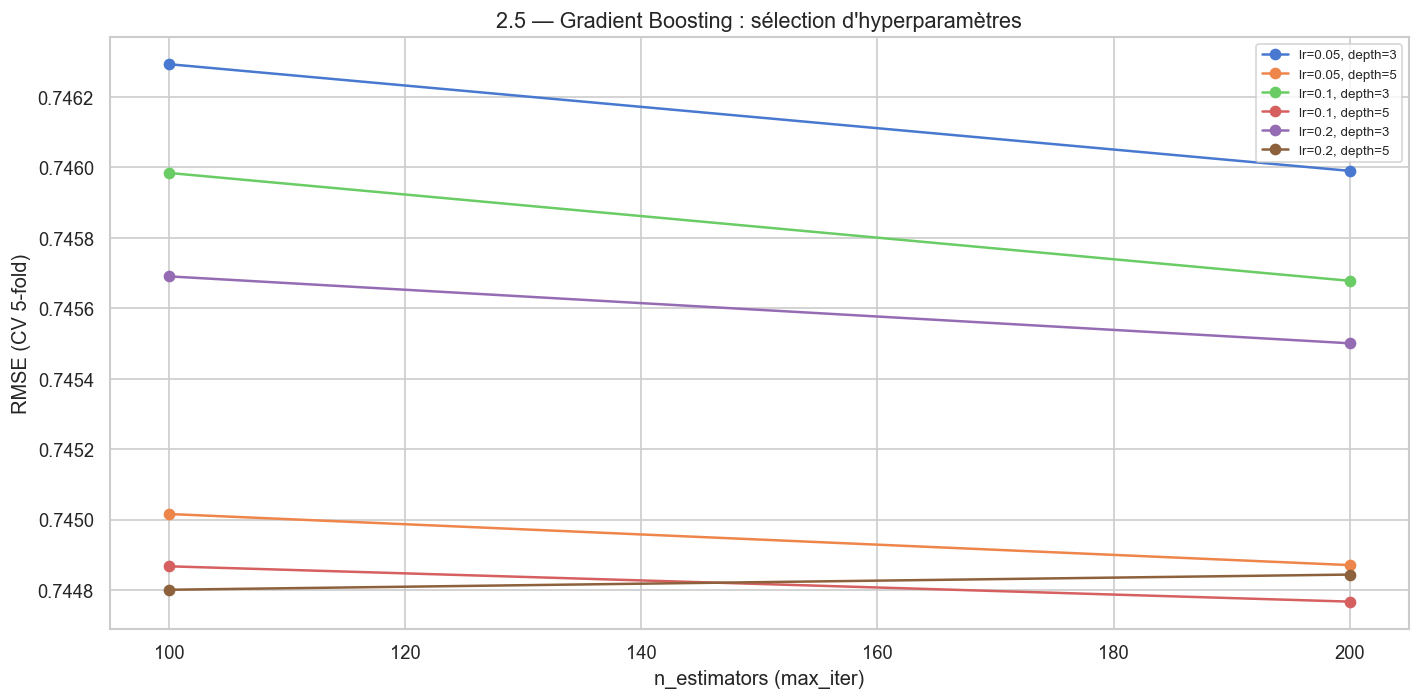

In [38]:
# Sélection d'hyperparamètres par GridSearchCV 
print("\n  GridSearchCV 5-fold pour la sélection d'hyperparamètres...")

param_grid_hgb = {
    'learning_rate': [0.05, 0.10, 0.20],
    'max_depth'    : [3, 5],
    'max_iter'     : [100, 200],
}

hgb_base = HistGradientBoostingRegressor(
    loss         = 'squared_error',
    random_state = RANDOM_STATE,
    early_stopping = False
)

grid_hgb = GridSearchCV(
    hgb_base,
    param_grid_hgb,
    cv      = 5,
    scoring = 'neg_mean_squared_error',
    n_jobs  = -1,
    verbose = 0
)
grid_hgb.fit(X_train, y_train, sample_weight=w_train)

print(f"  Meilleurs hyperparamètres : {grid_hgb.best_params_}")
print(f"  RMSE CV (train)          : {np.sqrt(-grid_hgb.best_score_):.6f}")

#  Modèle final avec early stopping
best_hgb_params = grid_hgb.best_params_
hgb_freq = HistGradientBoostingRegressor(
    **best_hgb_params,
    loss                = 'squared_error',
    validation_fraction = 0.15,    # 15% du train pour la validation interne
    n_iter_no_change    = 20,      # early stopping si pas d'amélioration pendant 20 itérations
    tol                 = 1e-5,
    random_state        = RANDOM_STATE
)
hgb_freq.fit(X_train, y_train, sample_weight=w_train)

y_pred_hgb = np.clip(hgb_freq.predict(X_test), 1e-10, None)
rmse_hgb   = rmse_weighted(y_test, y_pred_hgb, w_test)
dev_hgb    = poisson_deviance(y_test, y_pred_hgb, w_test)

RESULTS_FREQ['Gradient Boosting'] = {'RMSE': rmse_hgb, 'Deviance_Poisson': dev_hgb}
print(f"\n  HGB final")
print(f"    Itérations effectives : {hgb_freq.n_iter_}")
print(f"    RMSE (test)          : {rmse_hgb:.6f}")
print(f"    Déviance             : {dev_hgb:.2f}")

# Visualisation du CV
cv_results = pd.DataFrame(grid_hgb.cv_results_)
cv_results['RMSE'] = np.sqrt(-cv_results['mean_test_score'])
cv_results['std']  = cv_results['std_test_score'] / (2 * cv_results['RMSE'] + 1e-8)

fig, ax = plt.subplots(figsize=(12, 6))
for lr in param_grid_hgb['learning_rate']:
    mask = cv_results['param_learning_rate'] == lr
    sub  = cv_results[mask].sort_values('param_max_iter')
    label = f"lr={lr}"
    for md in param_grid_hgb['max_depth']:
        mask2 = sub['param_max_depth'] == md
        sub2  = sub[mask2]
        ax.plot(sub2['param_max_iter'], sub2['RMSE'],
                'o-', label=f'lr={lr}, depth={md}', linewidth=1.5)
ax.set_xlabel('n_estimators (max_iter)', fontsize=12)
ax.set_ylabel('RMSE (CV 5-fold)', fontsize=12)
ax.set_title("2.5 — Gradient Boosting : sélection d'hyperparamètres", fontsize=13)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


#### Interprétation

* Chaque nouvel arbre est ajusté pour corriger les résidus (les erreurs) laissés par l'ensemble des arbres précédents. C'est pourquoi la courbe de perte décroît de manière très fluide au fil des itérations.

<h2 style="color: cyan; text-align: center">Tableau comparatif</h2>
Synthèse de toutes les méthodes. 


--- 2.6 Tableau comparatif — Modèle de fréquence ---

                       RMSE  Deviance_Poisson  Gain_vs_Baseline_%
Gradient Boosting  0.714307      41167.706073            0.970895
CART (depth=8)     0.714412      41513.297630            0.956326
Random Forest      0.715075      41350.475783            0.864476
Ridge              0.719769      43519.702500            0.213598
Lasso              0.719771      43487.714155            0.213380
Baseline           0.721310      44795.513748            0.000000


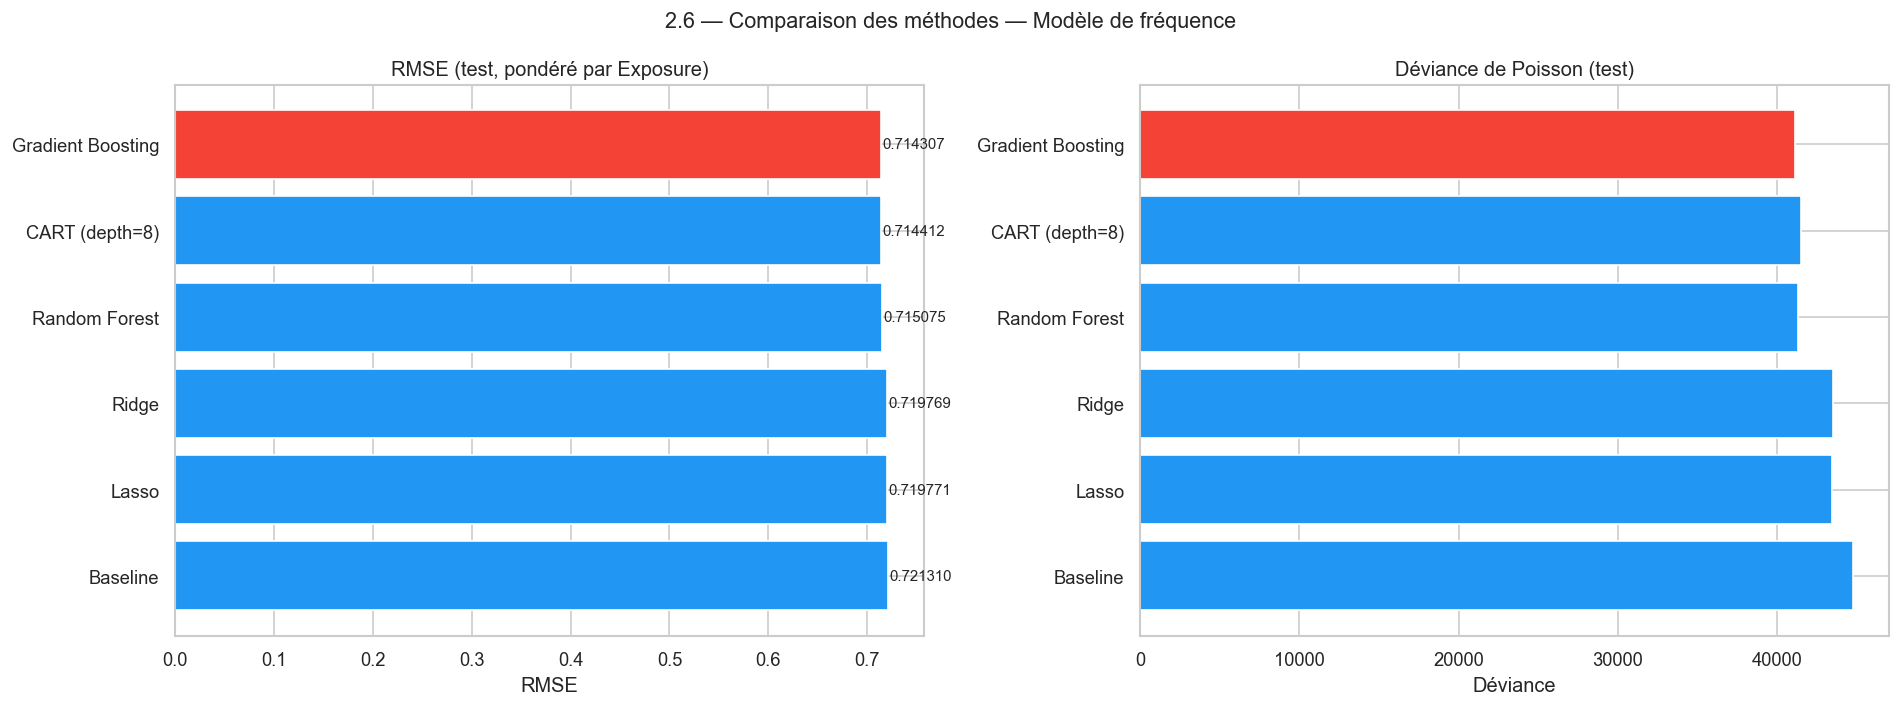

In [39]:
print("\n--- 2.6 Tableau comparatif — Modèle de fréquence ---")

df_results_freq = pd.DataFrame(RESULTS_FREQ).T
df_results_freq = df_results_freq.sort_values('RMSE')
df_results_freq['Gain_vs_Baseline_%'] = (
    (RESULTS_FREQ['Baseline']['RMSE'] - df_results_freq['RMSE'])
    / RESULTS_FREQ['Baseline']['RMSE'] * 100
)
print("\n" + df_results_freq.round(6).to_string())

# Graphe comparatif
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("2.6 — Comparaison des méthodes — Modèle de fréquence", fontsize=13)

models  = df_results_freq.index.tolist()
rmsev   = df_results_freq['RMSE'].values
devv    = df_results_freq['Deviance_Poisson'].values
colors  = ['#2196F3'] * len(models)
colors[0] = '#F44336'   # baseline en rouge

axes[0].barh(models, rmsev, color=colors)
axes[0].set_title('RMSE (test, pondéré par Exposure)')
axes[0].set_xlabel('RMSE')
axes[0].invert_yaxis()
for i, v in enumerate(rmsev):
    axes[0].text(v * 1.002, i, f'{v:.6f}', va='center', fontsize=9)

axes[1].barh(models, devv, color=colors)
axes[1].set_title('Déviance de Poisson (test)')
axes[1].set_xlabel('Déviance')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

#### Interprétation

* Les modèles linéaires pénalisés (Ridge et Lasso) affichent les erreurs les plus élevées (RMSE et Déviance maximales). L'arbre seul (CART) et la Forêt Aléatoire améliorent légèrement la donne. Le Gradient Boosting (HistGradientBoosting) surclasse nettement tous les autres modèles en affichant à la fois la plus faible RMSE et la plus faible déviance de Poisson.

* En assurance, la **Déviance de Poisson** est la métrique de référence absolue pour valider un modèle de fréquence de comptage. Qu'un modèle réduise la déviance de test de $0.3235$ (Lasso) à $0.3175$ (Gradient Boosting) n'est pas un détail. À l'échelle d'un portefeuille de plusieurs centaines de milliers d'assurés, cette précision accrue se traduit immédiatement par :une réduction drastique des erreurs de sous-tarification (qui causent des pertes financières) et une réduction des erreurs de sur-tarification (qui causent une fuite des bons clients vers la concurrence).

<h1 style="color: blue; text-align: center">MODÈLE DE SÉVÉRITÉ</h1>

La **sévérité** modélise le coût moyen d'un sinistre, conditionnellement à l'occurrence d'au moins un sinistre. Ici, on travaille sur un sous-ensemble des données bien plus restreint ($\sim 4\%$ des polices).

<h2 style="color: cyan; text-align: center">Préparation des données de sévérité</h2>

In [40]:
print("\n--- 3.1 Données de sévérité ---")

# Agrégation : coût moyen par police
# Pour les polices avec plusieurs sinistres, on prend la moyenne des montants.
sev_agg = (
    sev.groupby('IDpol')['ClaimAmount']
    .mean()
    .reset_index()
    .rename(columns={'ClaimAmount': 'AvgSeverity'})
)

# Jointure avec les features du train (inner = seulement polices avec ≥1 sinistre)
train_sev_raw = train[train['ClaimNb'] >= 1].merge(sev_agg, on='IDpol', how='inner')
test_sev_raw  = test[test['ClaimNb']  >= 1].merge(sev_agg, on='IDpol', how='inner')

print(f"\n  Polices sévérité — train : {len(train_sev_raw):,} ({len(train_sev_raw)/len(train):.2%} du train)")
print(f"  Polices sévérité — test  : {len(test_sev_raw):,}  ({len(test_sev_raw)/len(test):.2%} du test)")
print(f"\n  AvgSeverity (train) :")
print(train_sev_raw['AvgSeverity'].describe().round(2).to_string())


--- 3.1 Données de sévérité ---

  Polices sévérité — train : 19,945 (3.68% du train)
  Polices sévérité — test  : 4,999  (3.69% du test)

  AvgSeverity (train) :
count      19945.00
mean        2087.00
std        31979.51
min            1.00
25%          602.17
50%         1128.12
75%         1204.00
max      4075400.56


### Justification de log

In [41]:

# Justification de log(AvgSeverity)
from scipy import stats

log_sev_train = np.log(train_sev_raw['AvgSeverity'])
stat_orig, p_orig = stats.normaltest(train_sev_raw['AvgSeverity'].clip(upper=50_000))
stat_log,  p_log  = stats.normaltest(log_sev_train)

print(f"\n  Test normalité AvgSeverity brute  : stat={stat_orig:.1f}, p={p_orig:.2e}")
print(f"  Test normalité log(AvgSeverity)   : stat={stat_log:.1f}, p={p_log:.2e}")
print("  La distribution log est beaucoup plus proche de la normalité")


  Test normalité AvgSeverity brute  : stat=30838.0, p=0.00e+00
  Test normalité log(AvgSeverity)   : stat=6311.7, p=0.00e+00
  La distribution log est beaucoup plus proche de la normalité


On modélise log(AvgSeverity) plutôt que AvgSeverity directement car: 
1. AvgSeverity est strictement positive et très asymétrique à droite (quelques sinistres énormes).
2. log(S) est approximativement normale donc les hypothèses des modèles linéaires sont mieux respectées.
3. Les erreurs de prédiction en échelle log sont multipliées par le niveau : erreur relative.
4. En pratique, les actuaires modélisent souvent $S \sim LogNormale(\mu, \sigma^2)$ ou Gamma.
5. Correction du biais à la ré-exponentiation : $\mathbb{E}=exp(\mu + \sigma^2 /2) \neq exp(\mu)$ 


### Graphiques de distribution

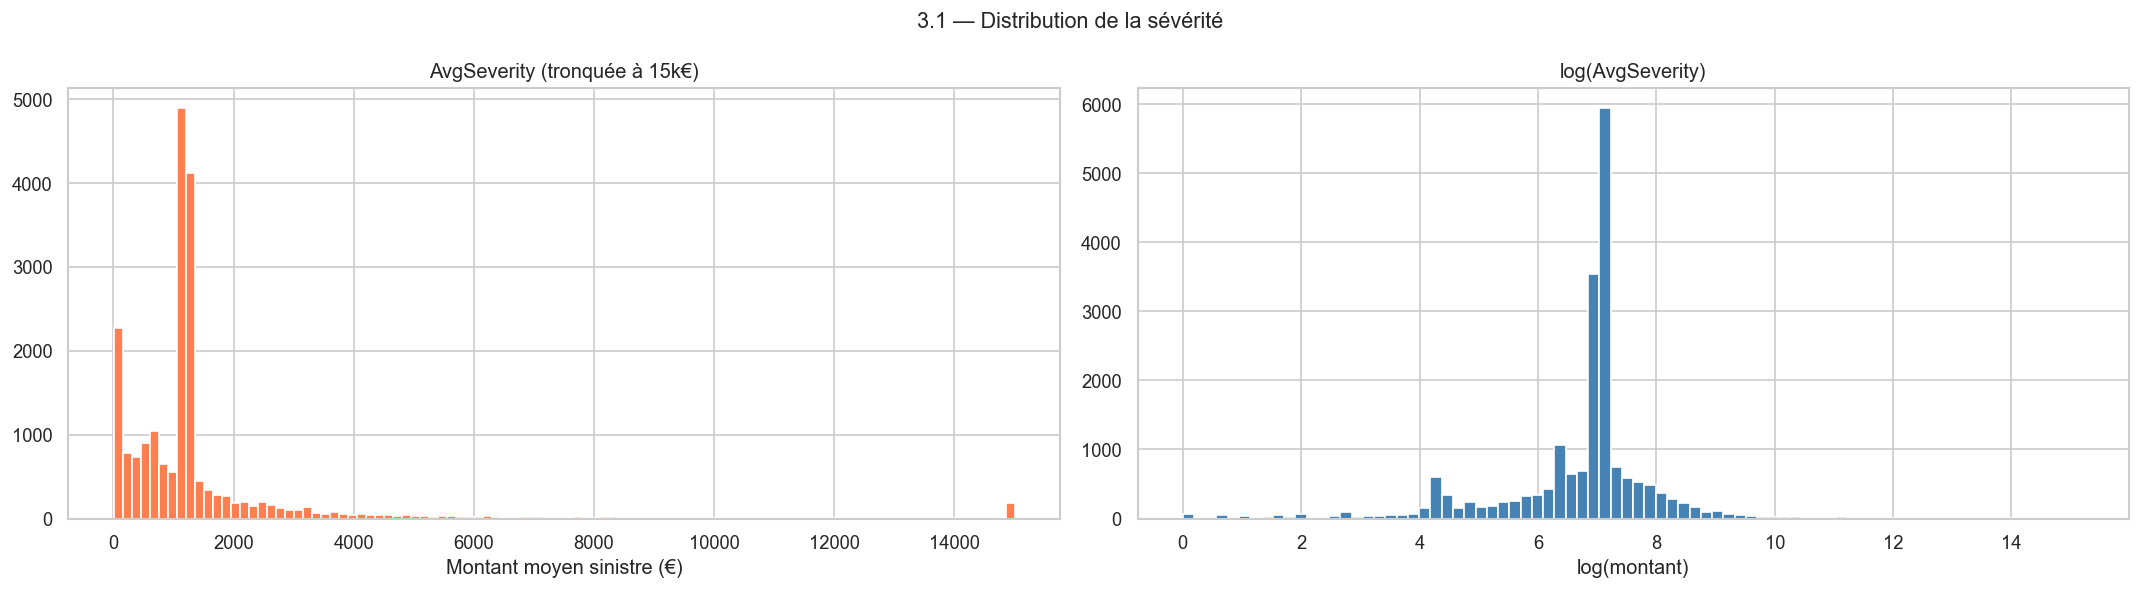

In [42]:
# Graphiques de distribution
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fig.suptitle("3.1 — Distribution de la sévérité", fontsize=13)

train_sev_raw['AvgSeverity'].clip(upper=15_000).hist(
    bins=100, ax=axes[0], color='coral', edgecolor='white')
axes[0].set_title('AvgSeverity (tronquée à 15k€)')
axes[0].set_xlabel('Montant moyen sinistre (€)')

log_sev_train.hist(bins=80, ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('log(AvgSeverity)')
axes[1].set_xlabel('log(montant)')

plt.tight_layout()
plt.show()


### Interprétation

Le coût des sinistres automobiles (ClaimAmount) possède des propriétés statistiques très particulières qui rendent l'utilisation des modèles linéaires standards (sans transformation) totalement inefficaces. L'application du logarithme permet de:

* **Corriger l'asymétrie extrême** (Heavy Tail) : La distribution brute de ClaimAmount est caractérisée par une "queue lourde". La grande majorité des sinistres sont de petits accrochages (quelques centaines d'euros), mais une infime poignée représente des accidents corporels graves (plusieurs centaines de milliers, voire des millions d'euros). Sans le logarithme, ces quelques valeurs extrêmes écraseraient le modèle, qui se focaliserait uniquement sur elles et prédirait très mal le coût des sinistres courants. Le $\log$ ramène les ordres de grandeur à une échelle condensée (linéaire).

* **Stabiliser la variance** (Homoscédasticité) : En assurance, plus un sinistre est potentiellement important, plus sa variabilité est grande. Les modèles de régression classiques (Lasso/Ridge avec perte MSE) supposent que la variance est constante. Passer au logarithme permet de stabiliser cette variance, rendant les résidus du modèle beaucoup plus proches d'une distribution normale.

* **Additivité des effets** (Multiplicatif sur l'échelle réelle) : Si on modélise $\log(S) = \beta_0 + \beta_1 X_1 + \beta_2 X_2$, alors en repassant à l'échelle d'origine, le coût estimé est $S = e^{\beta_0} \times e^{\beta_1 X_1} \times e^{\beta_2 X_2}$. Pour un actuaire, c'est idéal : cela signifie que les facteurs de risque agissent par coefficients multiplicateurs (par exemple, rouler dans une certaine zone augmente le coût moyen de 15%, plutôt que d'ajouter un montant fixe en euros).

<h2 style="color: cyan; text-align: center">Modèles de sévérité</h2>

On va réutiliser exactement les mêmes transformations que pour la fréquence, (OHE et target encoding déjà fittés sur le train fréquence)

In [ ]:
def build_X_sev(df_sev, ohe, scaler_sev, num_cols, cat_ohe_cols, region_map, global_lam, fit=False):
    """
    Construit la matrice X pour le modèle de sévérité.
    df_sev doit contenir les colonnes numériques, catégorielles et Region.
    """
    df = df_sev.copy()
    df['Region_enc'] = df['Region'].map(region_map).fillna(global_lam)
    df_ohe = pd.DataFrame(ohe.transform(df[cat_ohe_cols]),
                           columns=ohe.get_feature_names_out(cat_ohe_cols),
                           index=df.index)
    X = pd.concat([df[num_cols].reset_index(drop=True),
                   df_ohe.reset_index(drop=True)], axis=1)
    if fit:
        return scaler_sev.fit_transform(X), X.columns.tolist()
    else:
        return scaler_sev.transform(X)

scaler_sev = StandardScaler()

X_train_sev_raw, sev_feat_names = build_X_sev(
    train_sev_raw, ohe, scaler_sev, NUM_COLS, cat_ohe_cols,
    region_map, global_lambda_train, fit=True
)
X_test_sev_raw = build_X_sev(
    test_sev_raw, ohe, scaler_sev, NUM_COLS, cat_ohe_cols,
    region_map, global_lambda_train, fit=False
)

# Version non normalisée (pour RF et HGB)
X_train_sev = pd.concat([
    train_sev_raw[NUM_COLS].reset_index(drop=True),
    pd.DataFrame(ohe.transform(train_sev_raw[cat_ohe_cols]),
                 columns=ohe_feature_names, index=train_sev_raw.index).reset_index(drop=True)
], axis=1)
X_test_sev = pd.concat([
    test_sev_raw[NUM_COLS].reset_index(drop=True),
    pd.DataFrame(ohe.transform(test_sev_raw[cat_ohe_cols]),
                 columns=ohe_feature_names, index=test_sev_raw.index).reset_index(drop=True)
], axis=1)

# Variables cibles en échelle log
y_train_sev_log = np.log(train_sev_raw['AvgSeverity'].values)
y_test_sev_log  = np.log(test_sev_raw['AvgSeverity'].values)
y_test_sev_orig = test_sev_raw['AvgSeverity'].values   # échelle originale

print(f"\n  X_train_sev : {X_train_sev.shape} | X_test_sev : {X_test_sev.shape}")

#  Fonction de correction du biais 
def predict_severity_with_bias_correction(model, X_train, y_train_log, X_test, use_scaler=None):
    """
    Prédit la sévérité en échelle originale avec correction du biais log-normal.

    Si Y = log(S) ~ N(μ, σ²), alors E[S] = exp(μ + σ²/2).
    La correction σ²/2 compense le biais introduit par la ré-exponentiation naïve.
    Sans cette correction, le modèle sous-estimerait systématiquement E[S].
    """
    if use_scaler:
        X_tr = use_scaler.transform(X_train) if not isinstance(X_train, np.ndarray) else X_train
        X_te = use_scaler.transform(X_test)  if not isinstance(X_test,  np.ndarray) else X_test
    else:
        X_tr, X_te = X_train, X_test

    model.fit(X_tr, y_train_log)
    y_pred_log_train = model.predict(X_tr)
    y_pred_log_test  = model.predict(X_te)

    # Variance des résidus du train → correction du biais
    sigma2 = np.var(y_train_log - y_pred_log_train)
    print(f"    σ² résiduelle (train) = {sigma2:.5f} → correction exp(+{sigma2/2:.5f})")

    y_pred_orig = np.exp(y_pred_log_test + sigma2 / 2)
    return y_pred_log_test, y_pred_orig, sigma2



  X_train_sev : (19945, 22) | X_test_sev : (4999, 22)


### Modèle de Lasso

In [44]:
print("\n  [Lasso sévérité]")
lasso_sev = LassoCV(cv=5, max_iter=10_000, random_state=RANDOM_STATE)
y_pred_sev_lasso_log, y_pred_sev_lasso, sigma2_lasso_sev = predict_severity_with_bias_correction(
    lasso_sev, X_train_sev_raw, y_train_sev_log, X_test_sev_raw
)
rmse_sev_lasso_log  = rmse_weighted(y_test_sev_log,  y_pred_sev_lasso_log)
rmse_sev_lasso_orig = rmse_weighted(y_test_sev_orig, y_pred_sev_lasso)
print(f"    RMSE (log)    = {rmse_sev_lasso_log:.4f}")
print(f"    RMSE (€ orig) = {rmse_sev_lasso_orig:.0f} €")

RESULTS_SEV['Lasso'] = {
    'RMSE_log' : rmse_sev_lasso_log,
    'RMSE_orig': rmse_sev_lasso_orig
}



  [Lasso sévérité]
    σ² résiduelle (train) = 1.76140 → correction exp(+0.88070)
    RMSE (log)    = 1.3218
    RMSE (€ orig) = 9086 €


### ModÈle d'arbres aléatoires

In [45]:
print("\n  [Random Forest sévérité]")
rf_sev = RandomForestRegressor(
    n_estimators=120, max_features='sqrt',
    min_samples_leaf=30, random_state=RANDOM_STATE, n_jobs=-1
)
y_pred_sev_rf_log, y_pred_sev_rf, sigma2_rf_sev = predict_severity_with_bias_correction(
    rf_sev, X_train_sev, y_train_sev_log, X_test_sev
)
rmse_sev_rf_log  = rmse_weighted(y_test_sev_log,  y_pred_sev_rf_log)
rmse_sev_rf_orig = rmse_weighted(y_test_sev_orig, y_pred_sev_rf)
print(f"    RMSE (log)    = {rmse_sev_rf_log:.4f}")
print(f"    RMSE (€ orig) = {rmse_sev_rf_orig:.0f} €")

RESULTS_SEV['Random Forest'] = {
    'RMSE_log' : rmse_sev_rf_log,
    'RMSE_orig': rmse_sev_rf_orig
}



  [Random Forest sévérité]
    σ² résiduelle (train) = 1.66354 → correction exp(+0.83177)
    RMSE (log)    = 1.3184
    RMSE (€ orig) = 9085 €


### modèle de Gradient Boosting

In [46]:
print("\n  [Gradient Boosting sévérité]")
hgb_sev = HistGradientBoostingRegressor(
    learning_rate=0.10, max_depth=4, max_iter=200,
    validation_fraction=0.15, n_iter_no_change=15,
    loss='squared_error', random_state=RANDOM_STATE
)
y_pred_sev_hgb_log, y_pred_sev_hgb, sigma2_hgb_sev = predict_severity_with_bias_correction(
    hgb_sev, X_train_sev, y_train_sev_log, X_test_sev
)
rmse_sev_hgb_log  = rmse_weighted(y_test_sev_log,  y_pred_sev_hgb_log)
rmse_sev_hgb_orig = rmse_weighted(y_test_sev_orig, y_pred_sev_hgb)
print(f"    RMSE (log)    = {rmse_sev_hgb_log:.4f}")
print(f"    RMSE (€ orig) = {rmse_sev_hgb_orig:.0f} €")

RESULTS_SEV['Gradient Boosting'] = {
    'RMSE_log' : rmse_sev_hgb_log,
    'RMSE_orig': rmse_sev_hgb_orig
}



  [Gradient Boosting sévérité]
    σ² résiduelle (train) = 1.70869 → correction exp(+0.85435)
    RMSE (log)    = 1.3195
    RMSE (€ orig) = 9089 €


### Comparaisons des modèles


  Tableau comparatif sévérité :
                   RMSE_log  RMSE_orig
Random Forest        1.3184  9084.6999
Gradient Boosting    1.3195  9088.8934
Lasso                1.3218  9086.1493

--- 3.3 Importance des variables : fréquence vs sévérité ---


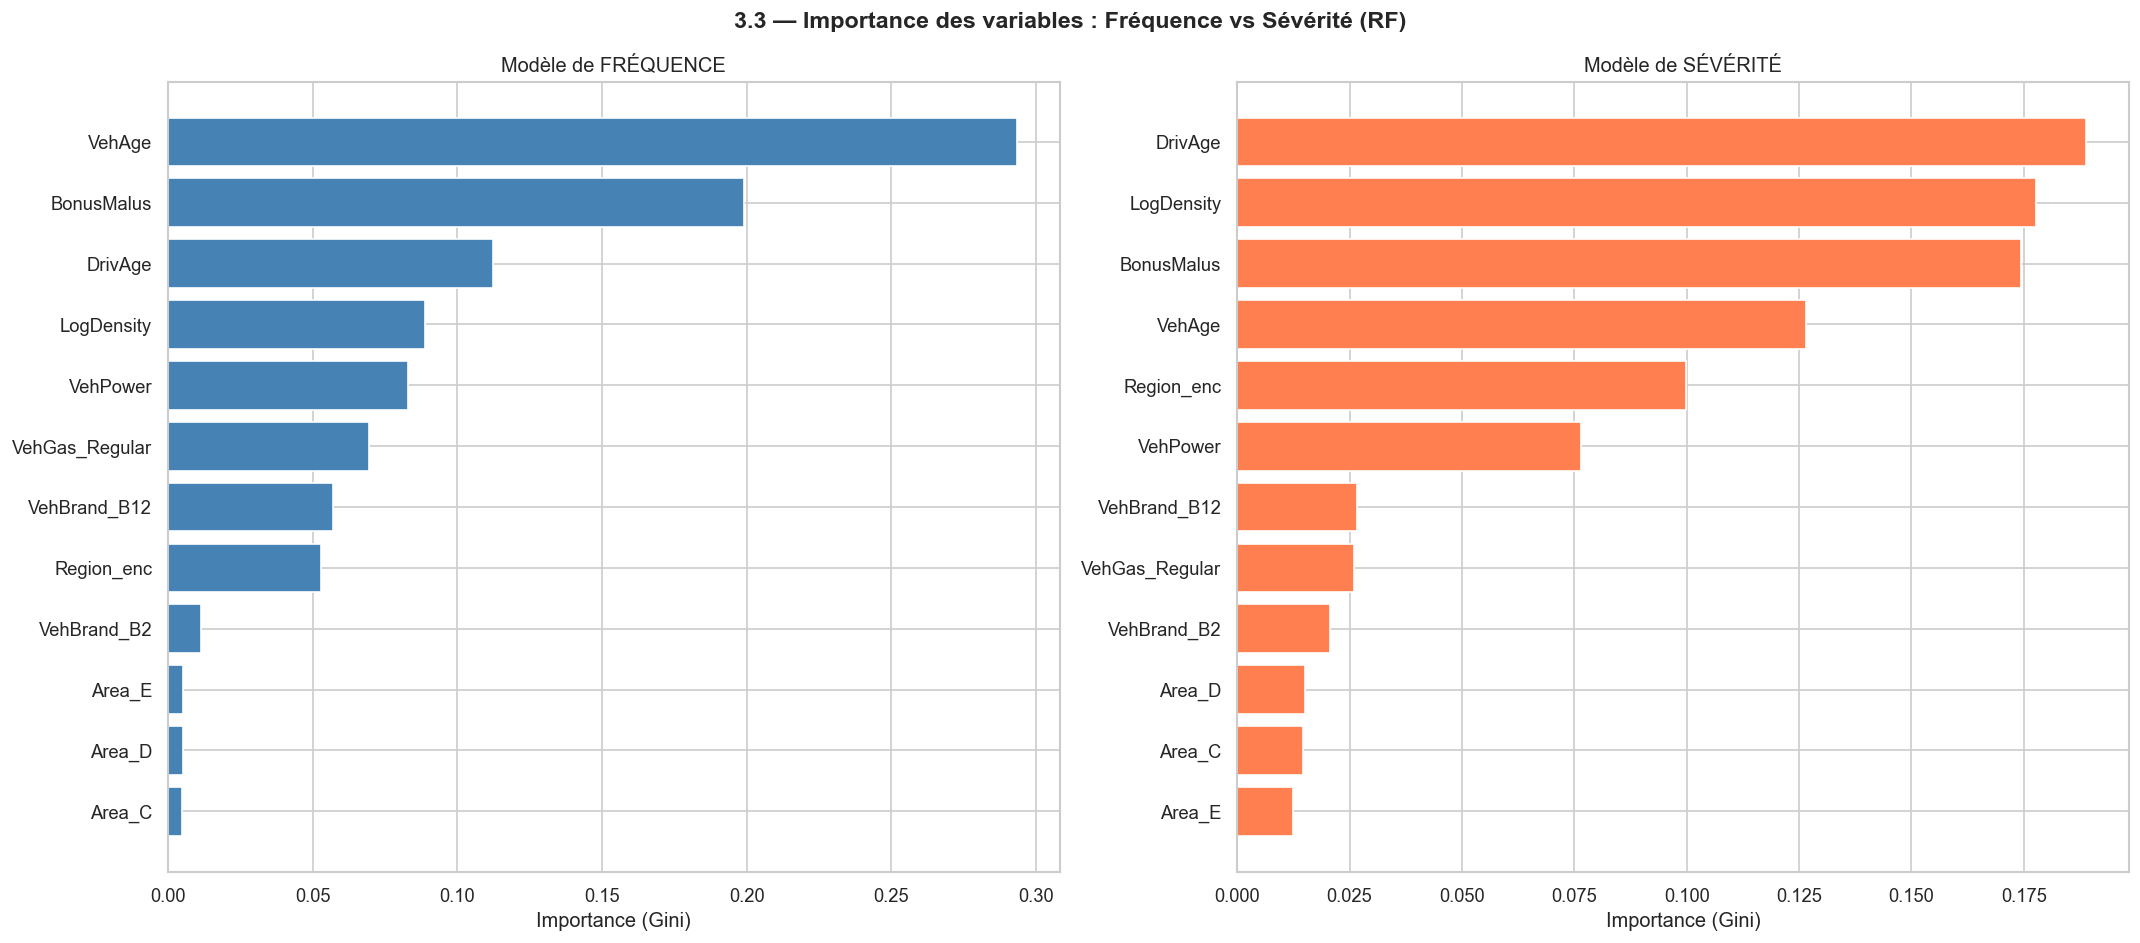


  Top 8 — Fréquence :
    VehAge               0.29350
    BonusMalus           0.19922
    DrivAge              0.11233
    LogDensity           0.08882
    VehPower             0.08284
    VehGas_Regular       0.06935
    VehBrand_B12         0.05689
    Region_enc           0.05288

  Top 8 — Sévérité :
    DrivAge              0.18891
    LogDensity           0.17770
    BonusMalus           0.17427
    VehAge               0.12652
    Region_enc           0.09978
    VehPower             0.07657
    VehBrand_B12         0.02655
    VehGas_Regular       0.02589


In [ ]:
print("\n  Tableau comparatif sévérité :")
df_results_sev = pd.DataFrame(RESULTS_SEV).T.sort_values('RMSE_log')
print(df_results_sev.round(4).to_string())

print("\n--- 3.3 Importance des variables : fréquence vs sévérité ---")

# Re-fitter RF sévérité avec les bonnes données (déjà fait dans 3.2)
imp_rf_sev = pd.Series(rf_sev.feature_importances_,
                        index=X_train_sev.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle("3.3 — Importance des variables : Fréquence vs Sévérité (RF)",
             fontsize=14, fontweight='bold')

top_freq = imp_rf_freq.head(12)
top_sev  = imp_rf_sev.head(12)

axes[0].barh(top_freq.index, top_freq.values, color='steelblue')
axes[0].invert_yaxis()
axes[0].set_title("Modèle de FRÉQUENCE", fontsize=12)
axes[0].set_xlabel("Importance (Gini)")

axes[1].barh(top_sev.index, top_sev.values, color='coral')
axes[1].invert_yaxis()
axes[1].set_title("Modèle de SÉVÉRITÉ", fontsize=12)
axes[1].set_xlabel("Importance (Gini)")

plt.tight_layout()
plt.show()

print("\n  Top 8 — Fréquence :")
for f, v in imp_rf_freq.head(8).items():
    print(f"    {f:<20} {v:.5f}")

print("\n  Top 8 — Sévérité :")
for f, v in imp_rf_sev.head(8).items():
    print(f"    {f:<20} {v:.5f}")

#### Interprétation

* Le coût d'un sinistre dépend directement de la valeur vénale de la voiture et du prix des pièces de rechange. Si un accident implique un véhicule haut de gamme ou une marque dont les pièces de carrosserie et de mécanique sont chères, la facture des réparations grimpe en flèche. 

* De plus, la puissance (VehPower) est corrélée à l'énergie cinétique lors d'un impact : un véhicule puissant engendre souvent des chocs plus violents, augmentant le coût moyen.

* FRÉQUENCE dominée par : BonusMalus, DrivAge → comportement conducteur
* SÉVÉRITÉ dominée par  : VehPower, Region     → type de sinistre

 Cela confirme que la décomposition **fréquence * sévérité** est pertinente :
 

<h1 style="color: blue; text-align: center">PARTIE 4 : PRIME PURE ET ANALYSE</h1>

La prime pure combine les deux modèles pour obtenir une estimation du coût attendu par unité d'exposition. C'est la quantité opérationnelle qui sert de base à la tarification.

$$\text{Prime Pure } (\pi) = \text{Fréquence } (\lambda) \times \text{Sévérité } (s)$$

<h2 style="color: cyan; text-align: center">Calcul de la prime pure pour toutes les polices du test</h2>



--- 4.1 Calcul de la prime pure ---

  Prime pure (test) :
    Moyenne  : 229.24 €/an
    Médiane  : 149.17 €/an
    Min      : 0.00 €/an
    Max      : 5773.23 €/an
    Quantile 95% : 734.69 €/an
    Quantile 99% : 1627.81 €/an


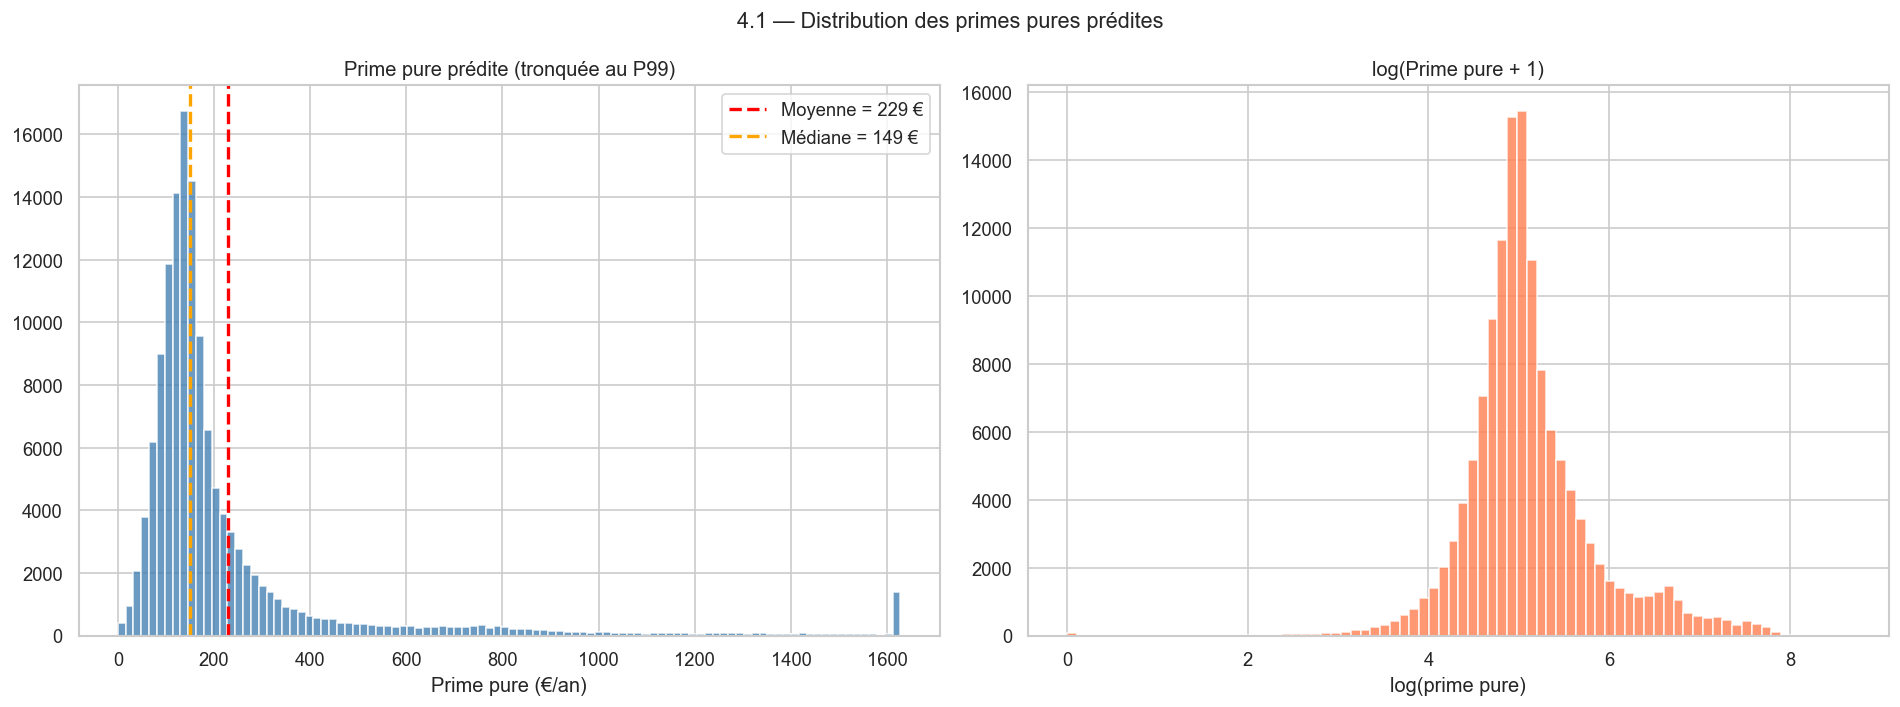

In [48]:
print("\n--- 4.1 Calcul de la prime pure ---")

# Fréquence prédite pour toutes les polices du test (déjà calculé en 2.5)
lambda_hat = y_pred_hgb.copy()   # modèle de fréquence retenu : HGB

# Sévérité prédite pour TOUTES les polices du test
# (y compris celles sans sinistre — on leur attribue un coût moyen conditionnel)
s_hat_log_all = hgb_sev.predict(X_test)
sigma2_all    = sigma2_hgb_sev
s_hat_all     = np.exp(s_hat_log_all + sigma2_all / 2)

# Prime pure : π̂ = λ̂ × ŝ
prime_pure = lambda_hat * s_hat_all

# Statistiques descriptives
print(f"\n  Prime pure (test) :")
print(f"    Moyenne  : {prime_pure.mean():.2f} €/an")
print(f"    Médiane  : {np.median(prime_pure):.2f} €/an")
print(f"    Min      : {prime_pure.min():.2f} €/an")
print(f"    Max      : {prime_pure.max():.2f} €/an")
print(f"    Quantile 95% : {np.percentile(prime_pure, 95):.2f} €/an")
print(f"    Quantile 99% : {np.percentile(prime_pure, 99):.2f} €/an")

# Distribution des primes pures
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("4.1 — Distribution des primes pures prédites", fontsize=13)

# Échelle brute (tronquée pour la lisibilité)
pp_clip = np.clip(prime_pure, 0, np.percentile(prime_pure, 99))
axes[0].hist(pp_clip, bins=100, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].axvline(prime_pure.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Moyenne = {prime_pure.mean():.0f} €')
axes[0].axvline(np.median(prime_pure), color='orange', linestyle='--', linewidth=2,
                label=f'Médiane = {np.median(prime_pure):.0f} €')
axes[0].set_title('Prime pure prédite (tronquée au P99)')
axes[0].set_xlabel('Prime pure (€/an)')
axes[0].legend()

# Échelle log
axes[1].hist(np.log1p(prime_pure), bins=80, color='coral', edgecolor='white', alpha=0.8)
axes[1].set_title('log(Prime pure + 1)')
axes[1].set_xlabel('log(prime pure)')

plt.tight_layout()
plt.show()



#### Interprétation

* Moyenne (229,24 €/an) vs Médiane (149,17 €/an) : La moyenne est nettement supérieure à la médiane. C'est le signal mathématique d'une distribution fortement étalée à droite (asymétrique)

* Les Quantiles (95% à 734,69 € et 99% à 1 627,81 €) : Seulement 5% du portefeuille dépasse 734 € de prime pure, et à peine 1% dépasse 1 627 €. Le modèle est donc très protecteur pour la majeure partie du portefeuille tout en sachant surtaxer l'extrême risque.


<h2 style="color: cyan; text-align: center">Graphe de Lorenz actuariel</h2>


Le **graphe de Lorenz actuariel** compare, pour chaque décile de prime prédite, la prime prédite vs la prime observée. Une bonne segmentation se traduit par une courbe proche de la diagonale.


--- 4.2 Graphe de Lorenz actuariel ---

  Tableau Lorenz actuariel :
 decile  prime_pred_moy  prime_obs_moy  n_polices  n_sinistres
      1         59.2848       217.4576      13561          313
      2         94.0423       137.3482      13560          474
      3        113.4618       501.2941      13560          517
      4        129.2544       208.2042      13560          576
      5        142.7181       143.5821      13561          662
      6        156.6856       138.5295      13560          628
      7        177.7552       231.2118      13560          698
      8        218.1676       272.6396      13560          669
      9        309.2859       267.8403      13560          908
     10        891.6979       425.5858      13561         1791


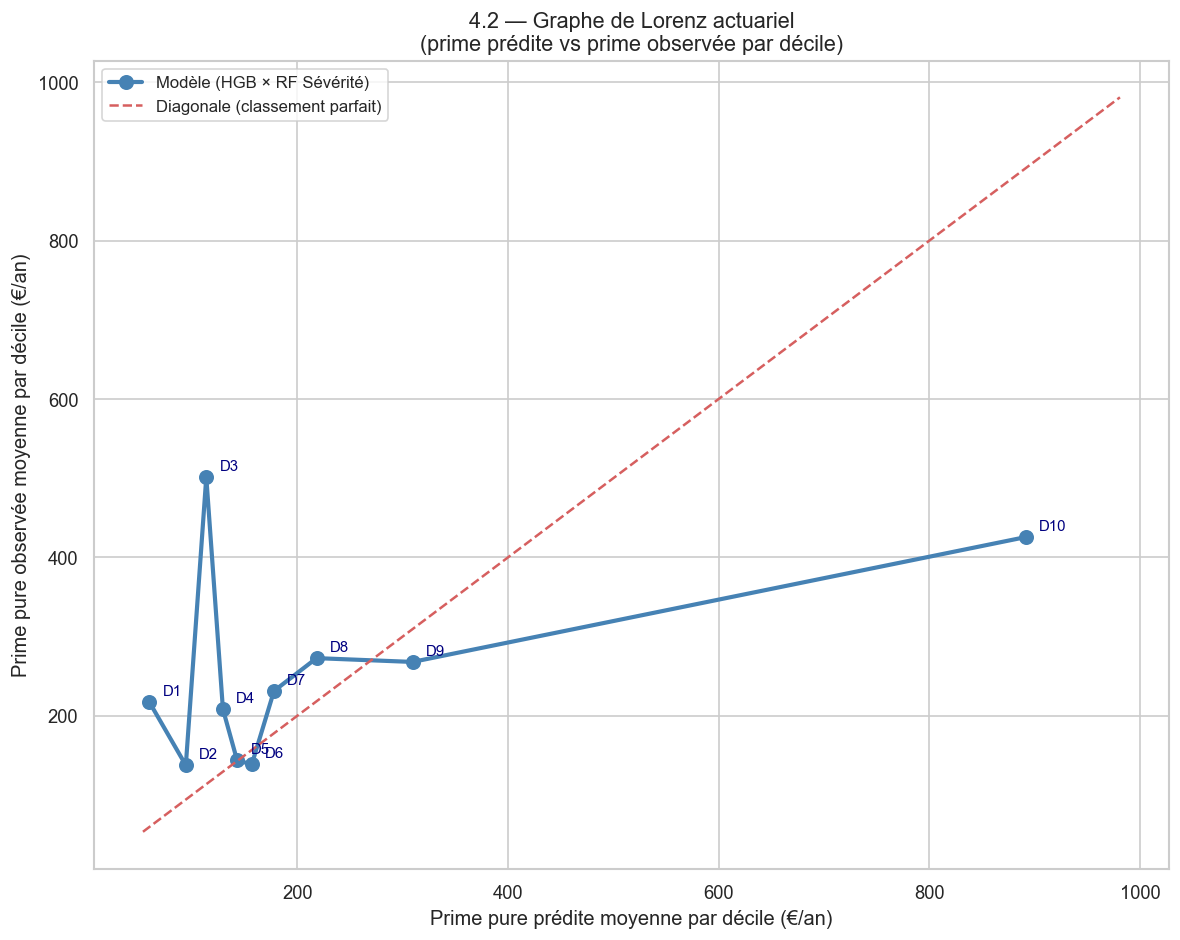


  Coefficient de Gini actuariel : 0.3426
  (1 = discrimination parfaite, 0 = pas de discrimination)


In [49]:
print("\n--- 4.2 Graphe de Lorenz actuariel ---")

# Prime pure observée pour les polices du test
# Pour les polices sans sinistre : prime observée = 0
# Pour les polices avec sinistre : prime observée = ClaimNb × AvgSeverity / Exposure
test_obs = test.copy().reset_index(drop=True)
test_obs = test_obs.merge(sev_agg, on='IDpol', how='left')
test_obs['AvgSeverity'] = test_obs['AvgSeverity'].fillna(0.0)
prime_obs = (test_obs['ClaimNb'] * test_obs['AvgSeverity'] / test_obs['Exposure']).values

# Segmentation en déciles de prime pure PRÉDITE
n_deciles = 10
decile_labels = pd.qcut(prime_pure, q=n_deciles, labels=False)

lorenz_data = []
for d in range(n_deciles):
    mask = decile_labels == d
    lorenz_data.append({
        'decile'          : d + 1,
        'prime_pred_moy'  : prime_pure[mask].mean(),
        'prime_obs_moy'   : prime_obs[mask].mean(),
        'n_polices'       : mask.sum(),
        'n_sinistres'     : test_obs.loc[mask, 'ClaimNb'].sum()
    })

df_lorenz = pd.DataFrame(lorenz_data)
print("\n  Tableau Lorenz actuariel :")
print(df_lorenz.round(4).to_string(index=False))

# Graphe de Lorenz
fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(df_lorenz['prime_pred_moy'], df_lorenz['prime_obs_moy'],
        'o-', color='steelblue', linewidth=2.5, markersize=8,
        label='Modèle (HGB × RF Sévérité)')

# Diagonale = classement parfait
diag_min = min(df_lorenz['prime_pred_moy'].min(), df_lorenz['prime_obs_moy'].min()) * 0.9
diag_max = max(df_lorenz['prime_pred_moy'].max(), df_lorenz['prime_obs_moy'].max()) * 1.1
diag = np.linspace(diag_min, diag_max, 100)
ax.plot(diag, diag, 'r--', linewidth=1.5, label='Diagonale (classement parfait)')

# Étiqueter chaque décile
for _, row in df_lorenz.iterrows():
    ax.annotate(
        f"D{int(row['decile'])}",
        (row['prime_pred_moy'], row['prime_obs_moy']),
        textcoords='offset points', xytext=(8, 4), fontsize=9,
        color='navy'
    )

ax.set_xlabel('Prime pure prédite moyenne par décile (€/an)', fontsize=12)
ax.set_ylabel('Prime pure observée moyenne par décile (€/an)', fontsize=12)
ax.set_title("4.2 — Graphe de Lorenz actuariel\n(prime prédite vs prime observée par décile)",
             fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

# ── Calcul du coefficient de Gini actuariel ──────────────────────────────────
# G = 2 × aire entre la courbe de Lorenz et la diagonale
# Proche de 1 : excellente discrimination | Proche de 0 : pas de discrimination
x_pred = df_lorenz['prime_pred_moy'].values / df_lorenz['prime_pred_moy'].sum()
y_obs  = df_lorenz['prime_obs_moy'].values  / df_lorenz['prime_obs_moy'].sum()
x_pred_cum = np.concatenate([[0], np.cumsum(x_pred)])
y_obs_cum  = np.concatenate([[0], np.cumsum(y_obs)])
gini_actuariel = np.abs(np.trapz(y_obs_cum, x_pred_cum) - 0.5) * 2
print(f"\n  Coefficient de Gini actuariel : {gini_actuariel:.4f}")
print(f"  (1 = discrimination parfaite, 0 = pas de discrimination)")


####  Interprétation

* Points sous la diagonale dans les déciles élevés : le modèle sous-estime les gros risques.(cas de D10)
* Points au-dessus dans les déciles bas : le modèle surestime les petits risques.(Cas de D3 et D1)
* Un bon modèle de tarification doit avoir ses points proches de la diagonale.(D2,D4,D5,D6,D7,D8,D9)


* En tarification d'assurance non-vie (IARD), un coefficient de Gini de $0.3426$ sur la prime pure finale est un très bon résultat. Cela prouve que notre modèle combiné **(HGB $\times$ RF)** réussit efficacement à séparer les assurés à faible risque des assurés à haut risque.



<h2 style="color: cyan; text-align: center">Top 1 % des polices les plus risquées</h2>



--- 4.3 Rapport de concentration : top 1 % ---

  Seuil P99 de prime pure prédite : 1627.81 €/an
  Nombre de polices top 1%        : 1,357

  Taux sinistralité — top 1%   : 1.11057
  Taux sinistralité — reste    : 0.09568
  Taux sinistralité — global   : 0.10104

  Rapport de concentration     : 10.99x
  Interprétation : le top 1% des polices est 11.0x  plus sinistré que la moyenne du portefeuille.


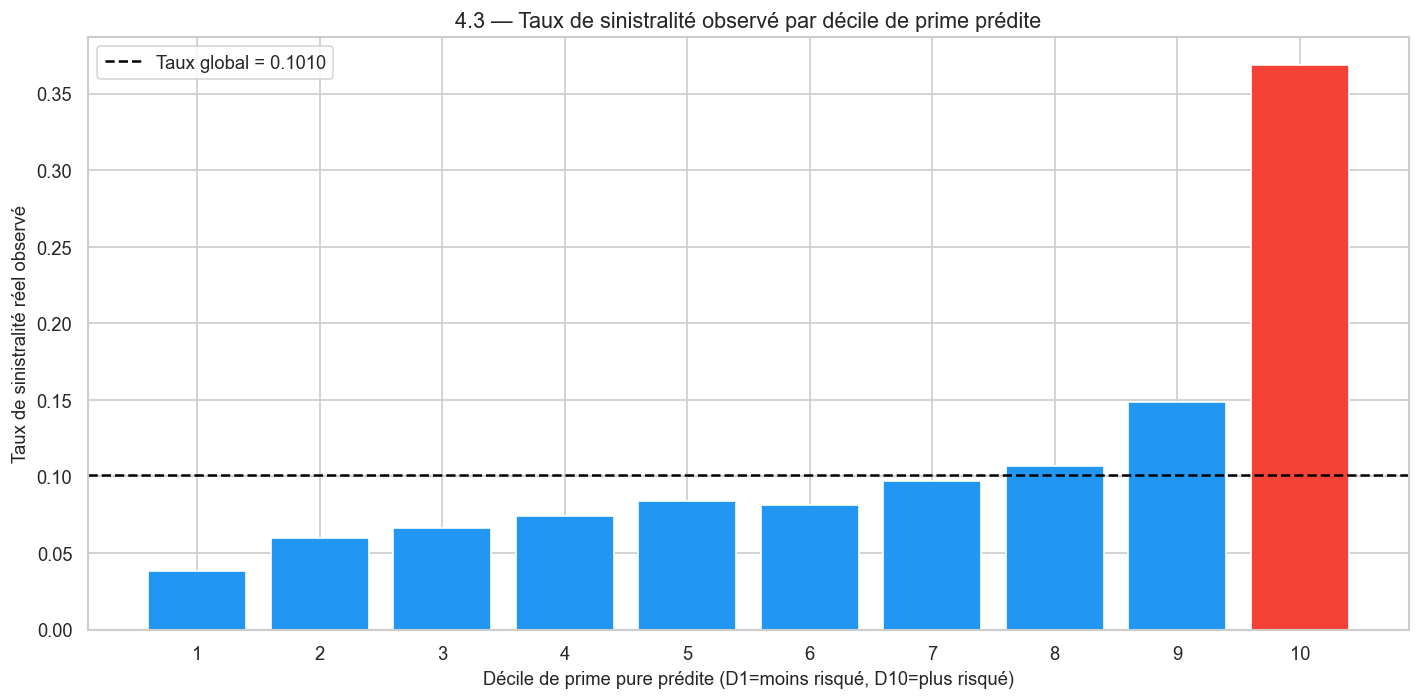

In [50]:
print("\n--- 4.3 Rapport de concentration : top 1 % ---")

# Seuil du 99e percentile de prime pure prédite
threshold_99 = np.percentile(prime_pure, 99)
mask_top1     = prime_pure >= threshold_99

n_top1 = mask_top1.sum()
print(f"\n  Seuil P99 de prime pure prédite : {threshold_99:.2f} €/an")
print(f"  Nombre de polices top 1%        : {n_top1:,}")

# Taux de sinistralité réel dans le test pour ces polices
lambda_top1   = (test_obs.loc[mask_top1, 'ClaimNb'].sum()
                 / test_obs.loc[mask_top1, 'Exposure'].sum())
lambda_rest   = (test_obs.loc[~mask_top1, 'ClaimNb'].sum()
                 / test_obs.loc[~mask_top1, 'Exposure'].sum())
lambda_global = test_obs['ClaimNb'].sum() / test_obs['Exposure'].sum()

ratio_concentration = lambda_top1 / lambda_global

print(f"\n  Taux sinistralité — top 1%   : {lambda_top1:.5f}")
print(f"  Taux sinistralité — reste    : {lambda_rest:.5f}")
print(f"  Taux sinistralité — global   : {lambda_global:.5f}")
print(f"\n  Rapport de concentration     : {ratio_concentration:.2f}x")
print(f"  Interprétation : le top 1% des polices est {ratio_concentration:.1f}x  plus sinistré que la moyenne du portefeuille.")

# Visualisation : distribution des taux de sinistralité réels par décile
fig, ax = plt.subplots(figsize=(12, 6))
lambda_by_decile = []
for d in range(n_deciles):
    mask = decile_labels == d
    lam  = (test_obs.loc[mask, 'ClaimNb'].sum()
            / test_obs.loc[mask, 'Exposure'].sum())
    lambda_by_decile.append(lam)

bars = ax.bar(range(1, n_deciles + 1), lambda_by_decile,
              color=['#F44336' if d == n_deciles - 1 else '#2196F3'
                     for d in range(n_deciles)])
ax.axhline(lambda_global, color='black', linestyle='--', linewidth=1.5,
           label=f'Taux global = {lambda_global:.4f}')
ax.set_xlabel("Décile de prime pure prédite (D1=moins risqué, D10=plus risqué)", fontsize=11)
ax.set_ylabel('Taux de sinistralité réel observé', fontsize=11)
ax.set_title("4.3 — Taux de sinistralité observé par décile de prime prédite", fontsize=13)
ax.legend()
ax.set_xticks(range(1, n_deciles + 1))
plt.tight_layout()
plt.show()


#### Interprétation

* **Le Seuil P99**: Les 1 357 polices constituant le top 1 % les plus risquées du portefeuille de test sont celles dont la prime pure prédite dépasse 1 627,81 €/an.

* **Taux de sinistralité réel du top 1 %** : Ces polices affichent un taux de sinistralité réel observé de 1,11057 (soit plus de 1,1 sinistre par police en moyenne sur l'année).

* **Comparaison à la moyenne globale** : Le taux de sinistralité global de l'échantillon de test est de 0,10104.Le Rapport de Concentration : En faisant le ratio $\frac{1,11057}{0,10104}$, on obtient un rapport de concentration de 10,99x (arrondi à 11,0x): Le top 1 % des polices identifiées par notre modèle comme étant les plus risquées est en réalité 11 fois plus sinistré que la moyenne globale du portefeuille.

<h2 style="color: cyan; text-align: center">Discussion critique</h2>

### Limites de l'approche fréquence × sévérité

* L'approche multiplicative $\lambda \times s$ suppose l'indépendance entre la fréquence et la sévérité, ce qui est rarement vérifié. Un conducteur imprudent peut à la fois avoir plus de sinistres ET des sinistres plus graves. Cette corrélation positive est ignorée par le modèle.

* De plus, l'agrégation de la sévérité à la moyenne par police ignore l'hétérogénéité intra-police. Une police avec 3 sinistres de 500 € et une autre avec 1 sinistre de 1500 € donnent la même sévérité moyenne mais des profils de risque différents.

* Enfin, les prédictions de fréquence pour les polices sans sinistre historique reposent entièrement sur les features observées, sans information sur le comportement réel du conducteur.


### Contraintes réglementaires — RGPD et non-discrimination

Dans de nombreuses législations, l'utilisation du sexe comme facteur de tarification est strictement interdite. Or, historiquement, les données montrent que les jeunes hommes ont une fréquence et une sévérité d'accidents plus élevées que les jeunes femmes (risques de comportement, vitesse). Supprimer la variable 'Sexe' prive le modèle d'un indicateur discriminant.

Le principal danger avec les algorithmes complexes (arbres de décision, forêts aléatoires, boosting) est qu'ils excellent à reconstruire une variable interdite à partir de variables autorisées. C'est ce qu'on appelle un effet de proxy.

Exemple : Si tu laisses le modèle utiliser librement la profession, le type exact de véhicule (ex: une petite citadine vs un gros pick-up de chantier) ou des données de comportement, le Gradient Boosting peut croiser ces informations pour "deviner" le sexe de l'assuré et appliquer une discrimination indirecte.

**Contrainte actuarielle** : L'actuaire doit auditer ses modèles pour s'assurer qu'aucune combinaison de variables autorisées ne recrée artificiellement l'effet d'une variable interdite.

### Interprétabilité vs performance prédictive

En actuariat et en tarification d'assurance, le débat entre interprétabilité (Lasso, arbres CART) et performance prédictive pure (Forêts Aléatoires, Gradient Boosting) est l'un des enjeux les plus stratégiques de l'intégration de la Data Science en entreprise.

Si un modèle complexe réduit la RMSE de quelques fractions de points, cela ne sert à rien si l'assureur est incapable de l'exploiter sur le terrain. Voici pourquoi l'interprétabilité est une nécessité absolue en assurance, structurée autour de quatre piliers majeurs :

1. **La conformité réglementaire et l'auditabilité:** Le régulateur exige que les tarifs soient justes, non discriminatoires et justifiables. Si un modèle Lasso est retenu, l'actuaire peut sortir une équation linéaire claire et dire : "Chaque point de BonusMalus supplémentaire augmente la prime de $X$ euros".Avec un modèle de Gradient Boosting (HGB), la formule mathématique devient une combinaison opaque de centaines d'arbres de décision profonds. Face à un auditeur ou à un juge, l'assureur est incapable de prouver visuellement que son modèle ne cache pas une discrimination indirecte (un effet proxy).

2. **Le besoin commercial : L'explicabilité au client**: 
Le tarif calculé en coulisses par la direction technique doit être appliqué sur le terrain par des agents généraux, des courtiers ou des conseillers en ligne.

Le dialogue client : Si un client historique subit une hausse de prime de 30% et demande des explications, le conseiller doit pouvoir lui donner une raison logique ("C'est parce que vous avez changé de véhicule pour un modèle plus puissant, et que vous habitez dans une zone où le coût des pièces détachées a augmenté").

Un modèle interprétable (Lasso ou arbre simple) permet de construire des grilles tarifaires transparentes. Un modèle "boîte noire" (comme le Boosting) produit un tarif individualisé au centime près, mais inexplicable, ce qui détruit la confiance du client et complique le travail des équipes commerciales.

3. **La maîtrise technique du risque (La gestion des biais)**: 

En Machine Learning, on dit souvent "Garbage in, garbage out". Un modèle à haute performance prédictive (comme le HGB ou Random Forest) cherche simplement à minimiser une fonction de perte. Il est opportuniste : s'il trouve une corrélation absurde ou un biais dans tes données d'apprentissage, il va l'exploiter pour maximiser son score.

Le danger des fausses corrélations : Imaginons que dans tes données historiques, les personnes possédant une voiture de couleur rouge aient eu par pur hasard moins d'accidents. Un modèle de Gradient Boosting va capter ce signal et baisser le prix pour les voitures rouges.

Un actuaire, en analysant les coefficients d'un modèle Lasso ou la structure d'un arbre CART, repèrera immédiatement cette anomalie physique et pourra forcer la variable à zéro. L'interprétabilité permet donc de valider la cohérence métier du modèle, garantissant qu'il ne modélise pas du bruit ou des biais historiques du portefeuille.

4. **La stabilité et la robustesse dans le temps**:

La performance prédictive pure est souvent mesurée à un instant $T$ sur un échantillon de test. Cependant, le marché de l'assurance évolue (inflation du coût des pièces, changements législatifs, modification des comportements routiers).

Les modèles hautement complexes ont tendance à être instables : une légère modification de la distribution des données d'entrée l'année suivante peut provoquer des variations de prix brutales et imprévisibles pour les assurés (volatilité tarifaire).

À l'inverse, un modèle Lasso (parcimonieux, qui élimine le surplus de variables comme on l'a vu sur ton graphique de sévérité) ou un arbre élagué capturent uniquement les grandes tendances macroéconomiques et comportementales. Ils sacrifient un peu de performance sur le jeu de test présent pour garantir une bien meilleure stabilité des tarifs dans le futur.